# **The Five-Factor Model of Personality and Evaluation of Drug Consumption Risk**

**Course:** ADY201m - AI, Data Science with Python & SQL

- **Project Title:** The Five Factor Model of personality and evaluation of drug consumption risk
- **Class Code:** AI2104
- **Group Name/ID:** Group 7
- **Member List:**
  1. Hoàng Trọng Hiếu - HE211206
  2. Nguyễn Quang Minh - HE211213
  3. Nguyễn Thái Bình Dương - HE211161
  4. Ngô Anh Duy - HE211165
- **Dataset Source Link:** https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified

**Phạm vi:** Phân loại việc tự báo cáo sử dụng ít nhất một trong tám chất thuộc Ecstasy pleiad trong tháng trước khảo sát. Kết quả mô tả mối liên hệ trong mẫu nghiên cứu và không dự đoán việc sử dụng chất trong tương lai.

**Contents**

- [1. Business Understanding](#section-1)
    - [1.1 Business Context and Project Justification](#section-1-1)
    - [1.2 Core Business Questions](#section-1-2)
    - [1.3 Data Science Problem Formulation](#section-1-3)
- [2. Dataset and Initial Inspection](#section-2)
    - [2.1 Data Dictionary](#section-2-1)
    - [2.2 Column Definition and Data Loading](#section-2-2)
    - [2.3 Feature Selection and Database Import](#section-2-3)
    - [2.4 Data Inspection](#section-2-4)
- [3. Data Cleaning](#section-3)
    - [3.1 Duplicate Data Checks](#section-3-1)
        - [3.1.1 Count Duplicate Rows](#section-3-1-1)
        - [3.1.2 Drop Duplicates](#section-3-1-2)
    - [3.2 Missing Value Checks](#section-3-2)
    - [3.3 Data Encoding and Format Standardization](#section-3-3)
    - [3.4 Data Type Casting and Verification](#section-3-4)
    - [3.5 Outlier Detection and Handling](#section-3-5)
    - [3.6 Data Cleaning Summary](#section-3-6)
- [4. Target Construction and Exploratory Data Analysis](#section-4)
    - [4.1 Target Construction and Univariate Analysis](#section-4-1)
    - [4.2 Bivariate Analysis](#section-4-2)
    - [4.3 Correlation Analysis](#section-4-3)
    - [4.4 Multivariate Analysis](#section-4-4)
- [5. Data Preparation](#section-5)
    - [5.1 Categorical Feature Encoding](#section-5-1)
    - [5.2 Train/Test Split and Feature Scaling](#section-5-2)
- [6. Baseline Model Training and Evaluation](#section-6)
    - [6.1 Baseline Model Training](#section-6-1)
    - [6.2 Model Comparison and Visualization](#section-6-2)
    - [6.3 Model Evaluation and Discussion](#section-6-3)
- [7. Discussion, Conclusions and Recommendations](#section-7)
    - [7.1 Core Findings and Model Summary (Kết quả chính và tổng kết mô hình)](#section-7-1)
    - [7.2 Actionable Business Recommendations (Đề xuất ứng dụng thực tế)](#section-7-2)
    - [7.3 Future Improvements and Limitations (Hạn chế và hướng phát triển)](#section-7-3)
    - [7.4 Evaluation Limitations and Reproducibility](#section-7-4)
    - [7.5 References](#section-7-5)

**Cách chạy:** Mở notebook từ thư mục gốc của repository và chạy toàn bộ các ô theo thứ tự. Sử dụng Python 3.11 cùng các thư viện trong `requirements.txt`. Notebook đọc `data/drug_consumption.data` và xây dựng lại các bảng `data_raw`, `data_clean` trong `database.sqlite3`; không cần chạy hai notebook nguồn trước.

<a id="business-understanding"></a>
<a id="section-1"></a>
# 1. Business Understanding

<a id="section-1-1"></a>
## 1.1 Business Context and Project Justification

- **Business Context:**
  - Việc sử dụng và lạm dụng các chất tác động lên thần kinh là vấn đề sức khỏe cộng đồng do những ảnh hưởng tiêu cực đối với cá nhân, gia đình và xã hội.
  
  - Hiểu rõ các đặc điểm liên quan đến hành vi sử dụng những chất này có thể hỗ trợ nghiên cứu và xây dựng hoạt động giáo dục phòng ngừa.
  
  - Bài báo nghiên cứu khả năng phân biệt người sử dụng và không sử dụng dựa trên đặc điểm tính cách, tính bốc đồng, xu hướng tìm kiếm cảm giác mạnh và thông tin nhân khẩu học.
  
  - Dựa trên nghiên cứu đó, dự án của nhóm tập trung vào nhóm Ecstasy pleiad, gồm tám chất có mối tương quan trong hành vi sử dụng. Mục tiêu là sử dụng thông tin nhân khẩu học và đặc điểm tính cách để phân loại một người có báo cáo sử dụng ít nhất một trong tám chất trong vòng một tháng gần nhất hay không.
- **Core Problem to Solve:**
  - Dự án của nhóm tập trung vào month-based Ecstasy pleiad: amphetamines, cannabis, cocaine, ketamine, LSD, mushrooms, legal highs, và ecstasy.
  
  - Người tham gia được cho là dương tính khi họ báo cáo rằng bản thân đã sử dụng 1 trong số những chất ở trên trong 1 tháng trước kể từ khi báo cáo.
  
  - Trong dự án này, nghiên cứu xem các yếu tố liên quan đến đặc điểm nhân khẩu học và tính cách có thể giúp phân loại những người này hay không.
- **Business Value / Significance:**
  - Phân tích này có thể hỗ trợ việc tìm ra mẫu chung trong việc sử dụng các chất gây nghiện trong thời gian gần đây, cũng như việc xây dựng các chương trình giáo dục nhằm ngăn chặn tình trạng nghiện ngập.

  - Kết quả không nên được sử dụng để chẩn đoán nghiện mà chỉ là để tham khảo.
  
  - Khảo sát dựa trên dữ liệu tự báo cáo, có thiết kế cắt ngang và sử dụng phương pháp tuyển mẫu kiểu “snowball” (lấy mẫu dây chuyền), đồng thời tồn tại sự mất cân đối đáng kể về đặc điểm nhân khẩu học.
  
  - Do đó, các kết quả chỉ phản ánh các mối liên hệ trong mẫu nghiên cứu này và không chứng minh nguy cơ sử dụng chất trong tương lai hay tỷ lệ hiện mắc trong toàn bộ dân số.

<a id="section-1-2"></a>
## 1.2 Core Business Questions

1. **Question 1:** Trong mẫu khảo sát, tỷ lệ User/Non-user của Ecstasy pleiad theo month-based là bao nhiêu? Nhãn có mất cân bằng nghiêm trọng không?
2. **Question 2:** Phân bố tuổi, giới tính, học vấn, đặc điểm tính cách Big Five, Impulsive và SS khác nhau như thế nào giữa hai nhóm? Đặc trưng nào có ảnh hưởng mạnh tới nhóm User/Non-user?
3. **Question 3:** Với cùng tập đặc trưng và quy trình đánh giá, Logistic Regression và Random Forest phân loại hai nhóm tốt đến đâu?

<a id="section-1-3"></a>
## 1.3 Data Science Problem Formulation

- **Problem Type:**
  - Binary Classification (Phân loại nhị phân)
- **Target Variable (y):**
  - Tên target variable là `User`, với các giá trị:
    - `1`: Có sử dụng ít nhất một chất thuộc cụm trong tháng trước khảo sát.
    - `0`: Không sử dụng chất nào thuộc cụm trong khoảng thời gian đó.
- **Expected Feature Variables (X):**
  - `Age` (tuổi), `Gender` (giới tính), `Education` (trình độ học vấn), `Nscore` (nhạy cảm với vấn đề tiêu cực), `Escore` (tính hướng ngoại), `Oscore` (tính cởi mở), `Ascore` (tính dễ chịu), `Cscore` (tính tận tâm), `Impulsive`, `SS`
- **Evaluation Metric:**
  - Sử dụng `F1-score` của lớp User làm chỉ số chính để so sánh hai mô hình baseline. Kiểm định chéo (Cross-validation) là bước mở rộng được đề xuất, chưa được triển khai trong báo cáo này.
  - Các chỉ số bổ sung gồm `Accuracy`, `Precision`, `Recall`, `ROC-AUC`, kết hợp `Confusion Matrix` để phân tích kết quả.

<a id="dataset-inspection"></a>
<a id="section-2"></a>
# 2. Dataset and Initial Inspection

<a id="section-2-1"></a>
## 2.1 Data Dictionary

Sử dụng dữ liệu `drug_consumption.data` từ bộ Drug Consumption (Quantified). Theo paper, nghiên cứu thu nhận 2.051 người và giữ 1.885 người sau kiểm tra tính hợp lệ. Tệp được cấp có 1.885 dòng, 32 cột, phân cách bằng dấu phẩy và không có dòng tiêu đề.

Source data: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified

**GROUP DATA DICTIONARY:**

| Số thứ tự | Cột | Kiểu dữ liệu | Ý nghĩa | Ví dụ |
| :--- | :--- | :--- | :--- | :--- |
| 1 | `ID` | Integer | Mã bản ghi, chỉ dùng đối chiếu | `1` |
| 2 | `Age` | Continuous | Nhóm tuổi | `0.49788` |
| 3 | `Gender` | Continuous | Giới tính theo bảng mã nguồn | `0.48246` |
| 4 | `Education` | Continuous | Trình độ học vấn | `-0.05921` |
| 5 | `Country` | Continuous | Quốc gia cư trú | `0.96082` |
| 6 | `Ethnicity` | Continuous | Nhóm sắc tộc | `0.126` |
| 7 | `Nscore` | Continuous | Neuroticism: nhạy cảm với cảm xúc tiêu cực | `0.31287` |
| 8 | `Escore` | Continuous | Extraversion: hướng ngoại | `-0.57545` |
| 9 | `Oscore` | Continuous | Openness: cởi mở với trải nghiệm | `-0.58331` |
| 10 | `Ascore` | Continuous | Agreeableness: dễ chịu/hợp tác | `-0.91699` |
| 11 | `Cscore` | Continuous | Conscientiousness: tận tâm | `-0.00665` |
| 12 | `Impulsive` | Continuous | Tính bốc đồng | `-0.21712` |
| 13 | `SS` | Continuous | Sensation seeking: Xu hướng tìm kiếm cảm giác mạnh | `-1.18084` |
| 14 | `Alcohol` | Categorical | Rượu/bia | `CL5` |
| 15 | `Amphet` | Categorical | Amphetamines | `CL2` |
| 16 | `Amyl` | Categorical | Amyl nitrite | `CL0` |
| 17 | `Benzos` | Categorical | Benzodiazepines | `CL2` |
| 18 | `Caff` | Categorical | Caffeine | `CL6` |
| 19 | `Cannabis` | Categorical | Cannabis | `CL0` |
| 20 | `Choc` | Categorical | Chocolate | `CL5` |
| 21 | `Coke` | Categorical | Cocaine | `CL0` |
| 22 | `Crack` | Categorical | Crack cocaine | `CL0` |
| 23 | `Ecstasy` | Categorical | Ecstasy | `CL0` |
| 24 | `Heroin` | Categorical | Heroin | `CL0` |
| 25 | `Ketamine` | Categorical | Ketamine | `CL0` |
| 26 | `Legalh` | Categorical | Legal highs | `CL0` |
| 27 | `LSD` | Categorical | LSD | `CL0` |
| 28 | `Meth` | Categorical | Methadone | `CL0` |
| 29 | `Mushrooms` | Categorical | Magic mushrooms | `CL0` |
| 30 | `Nicotine` | Categorical | Nicotine | `CL2` |
| 31 | `Semer` | Categorical | Semeron — chất giả để phát hiện sự thiếu trung thực trong khảo sát | `CL0` |
| 32 | `VSA` | Categorical | Chất bay hơi dùng qua hít | `CL0` |

<a id="section-2-2"></a>
## 2.2 Column Definition and Data Loading


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from contextlib import closing
from pathlib import Path

# Define the 32 source column names.
columns = [
    'ID', 'Age', 'Gender', 'Education', 'Country', 'Ethnicity',
    'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS',
    'Alcohol', 'Amphet', 'Amyl', 'Benzos', 'Caff', 'Cannabis',
    'Choc', 'Coke', 'Crack', 'Ecstasy', 'Heroin', 'Ketamine',
    'Legalh', 'LSD', 'Meth', 'Mushrooms', 'Nicotine', 'Semer', 'VSA'
]

# Read the .data file.
df_raw = pd.read_csv('data/drug_consumption.data', header=None, names=columns)

<a id="section-2-3"></a>
## 2.3 Feature Selection and Database Import


In [3]:
# Select demographic and psychological features plus the eight Ecstasy Pleiad substance columns.
selected_cols = [
    'ID', 'Age', 'Gender', 'Education', 'Country', 'Ethnicity',
    'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS',
    'Amphet', 'Cannabis', 'Coke', 'Ketamine', 'LSD', 'Mushrooms', 'Legalh', 'Ecstasy'
]
df_raw = df_raw[selected_cols]

# Import the selected raw data into SQLite.
database_path = "database.sqlite3"
with closing(sqlite3.Connection(database=database_path)) as connection:
    df_raw.to_sql(name="data_raw", if_exists="replace", index=False, con=connection)

# Create a new table 
with closing(sqlite3.Connection(database=database_path)) as connection:
    df_raw.to_sql(name="data_clean", if_exists="replace", index=False, con=connection)

<a id="section-2-4"></a>
## 2.4 Data Inspection


In [4]:
# Report the selected dataset dimensions.
print(f"Dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Inspect the selected data stored in SQLite.
with closing(sqlite3.Connection(database=database_path)) as connection:

    print("\n>>> First five records:")
    first_5_rows = pd.read_sql_query("SELECT * FROM data_raw ORDER BY ID ASC LIMIT 5", con=connection)
    display(first_5_rows)

    print("\n>>> Last five records:")
    last_5_rows = pd.read_sql_query("SELECT * FROM data_raw ORDER BY ID DESC LIMIT 5", con=connection)
    display(last_5_rows)

    print("\n>>>Data types, non-null counts, and memory usage:")
    retrieved_data = pd.read_sql_query("SELECT * FROM data_raw", con=connection)
    retrieved_data.info()

Dataset shape: 1885 rows, 21 columns

>>> First five records:


,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Impulsive,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,-0.21712,-1.18084,CL2,CL0,CL0,CL0,CL0,CL0,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,-0.71126,-0.21575,CL2,CL4,CL3,CL2,CL2,CL0,CL0,CL4
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,-1.37983,0.40148,CL0,CL3,CL0,CL0,CL0,CL1,CL0,CL0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,-1.37983,-1.18084,CL0,CL2,CL2,CL2,CL0,CL0,CL0,CL0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,-0.21712,-0.21575,CL1,CL3,CL0,CL0,CL0,CL2,CL1,CL1



>>> Last five records:


,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Impulsive,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy
0,1888,-0.95197,-0.48246,-0.61113,0.21128,-0.31685,-0.46725,2.12700,1.65653,1.11406,...,0.88113,1.22470,CL3,CL3,CL3,CL0,CL3,CL3,CL3,CL3
1,1887,-0.95197,0.48246,-0.61113,-0.57009,-0.31685,0.91093,-1.92173,0.29338,-1.62090,...,1.29221,1.22470,CL0,CL6,CL0,CL0,CL3,CL3,CL3,CL3
2,1886,-0.07854,0.48246,0.45468,-0.57009,-0.31685,1.13281,-1.37639,-1.27553,-1.77200,...,0.52975,-0.52593,CL6,CL6,CL4,CL2,CL2,CL2,CL0,CL4
3,1885,-0.95197,-0.48246,-0.61113,-0.57009,-0.31685,-0.24649,1.74091,0.58331,0.76096,...,0.88113,0.76540,CL0,CL3,CL0,CL0,CL5,CL4,CL3,CL2
4,1884,-0.95197,0.48246,-0.61113,-0.57009,-0.31685,-1.19430,1.74091,1.88511,0.76096,...,0.88113,1.92173,CL0,CL5,CL0,CL0,CL3,CL0,CL3,CL0



>>>Data types, non-null counts, and memory usage:
<class 'pandas.DataFrame'>
RangeIndex: 1885 entries, 0 to 1884
Data columns (total 21 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1885 non-null   int64  
 1   Age        1885 non-null   float64
 2   Gender     1885 non-null   float64
 3   Education  1885 non-null   float64
 4   Country    1885 non-null   float64
 5   Ethnicity  1885 non-null   float64
 6   Nscore     1885 non-null   float64
 7   Escore     1885 non-null   float64
 8   Oscore     1885 non-null   float64
 9   Ascore     1885 non-null   float64
 10  Cscore     1885 non-null   float64
 11  Impulsive  1885 non-null   float64
 12  SS         1885 non-null   float64
 13  Amphet     1885 non-null   str    
 14  Cannabis   1885 non-null   str    
 15  Coke       1885 non-null   str    
 16  Ketamine   1885 non-null   str    
 17  LSD        1885 non-null   str    
 18  Mushrooms  1885 non-null   str    
 19  Legalh  

<a id="section-2-4-1"></a>
### 2.4.1 Comments and Observations

- **Number of Records (Rows):**
  - Tổng cộng có 1.885 dòng (bản ghi).
- **Number of Attributes (Columns):**
  - 21 cột (gồm 1 ID, 12 đặc trưng nhân khẩu học & tâm lý, và 8 chất thuộc cụm Ecstasy pleiad).
- **Initial Observations on Data Types:**
  - Cột định danh (`ID`) mang kiểu số nguyên `int64`.
  - 12 đặc trưng nhân khẩu học và thang đo tâm lý `Age`, `Gender`, `Education`, `Country`, `Ethnicity`, `Nscore`, `Escore`, `Oscore`, `Ascore`, `Cscore`, `Impulsive`, `SS` đều mang kiểu số thực `float64`. Các biến phân loại nhân khẩu học đã được định lượng sẵn thành số thực ở dữ liệu gốc thay vì dạng nhãn thô.
  - 8 cột đo lường hành vi sử dụng chất kích thích mang kiểu `object`
  - Dữ liệu không chứa cột thời gian (`datetime`), toàn bộ 21 cột đều có 1.885 giá trị non-null.

<a id="data-cleaning"></a>
<a id="section-3"></a>
# 3. Data Cleaning

<a id="section-3-1"></a>
## 3.1 Duplicate Data Checks

<a id="section-3-1-1"></a>
### 3.1.1 Count Duplicate Rows


In [5]:
# 1. Count duplicate rows
with closing(sqlite3.connect("database.sqlite3")) as conn:
  cursor = conn.cursor()

  count_duplicate = """
    SELECT row_count
    FROM (
      SELECT COUNT(*) as row_count
      FROM data_raw
      GROUP BY 
        Age, Gender, Education, Country, Ethnicity,
        Nscore, Escore, Oscore, Ascore, Cscore, Impulsive, SS,
        Amphet, Cannabis, Coke, Ketamine,
        LSD, Mushrooms, Legalh, Ecstasy
      HAVING COUNT(*) > 1
    )
  """

  cursor.execute(count_duplicate)

  num_duplicates = cursor.fetchone()

  print(f"Number of duplicate rows detected: {num_duplicates}")


Number of duplicate rows detected: None


<a id="section-3-1-2"></a>
### 3.1.2 Drop Duplicates


In [6]:
if num_duplicates is not None:
  with closing(sqlite3.connect("database.sqlite3")) as conn:
    cursor = conn.cursor()

    delete_duplicate = """
      DELETE FROM data_clean
      WHERE ID NOT IN (
        SELECT MIN(ID)
        FROM data_clean
        GROUP BY 
          Age, Gender, Education, Country, Ethnicity,
          Nscore, Escore, Oscore, Ascore, Cscore, Impulsive, SS,
          Amphet, Cannabis, Coke, Ketamine,
          LSD, Mushrooms, Legalh, Ecstasy
      )
    """

    conn.commit()

with closing(sqlite3.Connection(database="database.sqlite3")) as conn:
  df_clean = pd.read_sql_query("SELECT * FROM data_clean", con=conn)
  print(f"\nDataset shape after handle duplicate data: {df_clean.shape}")


Dataset shape after handle duplicate data: (1885, 21)


**Comments and Observations**

  - Số lượng các bản ghi bị trùng lặp sau khi kiểm tra trùng lặp: 0
  - Do không có bản ghi nào bị trùng lặp nên sẽ không thực hiện bước xóa bỏ các bản ghi bị trùng lặp

<a id="section-3-2"></a>
## 3.2 Missing Value Checks

In [35]:
# 1. Summary of missing values
with closing(sqlite3.Connection(database="database.sqlite3")) as conn:
    cursor = conn.cursor()

    columns = df_clean.columns.to_list()
    missing = [0 for _ in range(len(columns))]

    for i, column in enumerate(columns):
        find_missing = f"""
            SELECT
                COUNT(*)
            FROM data_clean
            WHERE {column} IS NULL
        """

        cursor.execute(find_missing)
        result = cursor.fetchone()
        missing[i] = result[0]

    missing_df = pd.DataFrame({"Column": columns, "Missing Count": missing})
    display(missing_df)

# 2. Handle missing values column by column
print("There are no missing values in the dataset, so median/mode imputation or row removal is not necessary.")

# 3. Confirm zero remaining missing values
print(f"Total missing values after check and handle missing values: {df_clean.isnull().sum(axis=0).sum(axis=0)}")

,Column,Missing Count
0,ID,0
1,Age,0
2,Gender,0
3,Education,0
4,Country,0
5,Ethnicity,0
6,Nscore,0
7,Escore,0
8,Oscore,0
9,Ascore,0


There are no missing values in the dataset, so median/mode imputation or row removal is not necessary.
Total missing values after check and handle missing values: 0


<a id="section-3-2-1"></a>
### 3.2.1 Comments and Rationale

**Nhận xét:** Không có ô thiếu ở cả 21 cột; giữ nguyên dữ liệu. Không thêm bước bổ sung dữ liệu (imputation).


<a id="section-3-3"></a>
## 3.3 Data Encoding and Format Standardization

Encode categorical variables and standardize numeric representations before validating the mappings.

<a id="section-3-3-1"></a>
### 3.3.1 Substance-Use Label Encoding

In [8]:
def label_encoding(freq):
  if freq in ["CL6", "CL5", "CL4"]:
    return 1
  elif freq in ["CL3", "CL2", "CL1", "CL0"]:
    return 0
  return np.nan

for col in ["Amphet", "Cannabis", "Coke", "Ketamine", "LSD", "Mushrooms", "Legalh", "Ecstasy"]:
  df_clean[col] = df_clean[col].map(label_encoding)

df_clean.head()

,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Impulsive,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,-0.21712,-1.18084,0,0,0,0,0,0,0,0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,-0.71126,-0.21575,0,1,0,0,0,0,0,1
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,-1.37983,0.40148,0,0,0,0,0,0,0,0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,-1.37983,-1.18084,0,0,0,0,0,0,0,0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,-0.21712,-0.21575,0,0,0,0,0,0,0,0


<a id="section-3-3-2"></a>
### 3.3.2 Numeric Rounding and Category Mapping

In [9]:
# Handle floating-point representation errors
def truncate(x):
    return round(x, 5) if pd.notna(x) else x


features_columns = [
    "Age", "Gender", "Education", "Country", "Ethnicity",
    "Nscore", "Escore", "Oscore", "Ascore", "Cscore",
    "Impulsive", "SS"
]

for column in features_columns:
    df_clean[column] = df_clean[column].map(truncate)


# Ordinal and categorical encoding
mapping = {
  "Age": {
      -0.95197: 0,
      -0.07854: 1,
      0.49788: 2,
      1.09449: 3,
      1.82213: 4,
      2.59171: 5
  },
  "Gender": {
      0.48246: 0,
      -0.48246: 1
  },
  "Education": {
      -2.43591: 0,
      -1.73790: 1,
      -1.43719: 2,
      -1.22751: 3,
      -0.61113: 4,
      -0.05921: 5,
      0.45468: 6,
      1.16365: 7,
      1.98437: 8
  },
  "Country": {
      -0.09765: "Australia",
      0.24923: "Canada",
      -0.46841: "New Zealand",
      -0.28519: "Other",
      0.21128: "Republic of Ireland",
      0.96082: "UK",
      -0.57009: "USA"
  },
  "Ethnicity": {
      -0.50212: "Asian",
      -1.10702: "Black",
      1.90725: "Mixed-Black/Asian",
      0.12600: "Mixed-White/Asian",
      -0.22166: "Mixed-White/Black",
      0.11440: "Other",
      -0.31685: "White"
  }
}

# Apply mappings
mapping_columns = [
    "Age", "Gender", "Education", "Country", "Ethnicity"
]

for column in mapping_columns:
    df_clean[column] = df_clean[column].map(
        lambda x: mapping[column].get(x, np.nan)
    )

display(df_clean.head())

,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Impulsive,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy
0,1,2,0,5,UK,Mixed-White/Asian,0.31287,-0.57545,-0.58331,-0.91699,...,-0.21712,-1.18084,0,0,0,0,0,0,0,0
1,2,1,1,8,UK,White,-0.67825,1.93886,1.43533,0.76096,...,-0.71126,-0.21575,0,1,0,0,0,0,0,1
2,3,2,1,5,UK,White,-0.46725,0.80523,-0.84732,-1.62090,...,-1.37983,0.40148,0,0,0,0,0,0,0,0
3,4,0,0,7,UK,White,-0.14882,-0.80615,-0.01928,0.59042,...,-1.37983,-1.18084,0,0,0,0,0,0,0,0
4,5,2,0,8,UK,White,0.73545,-1.63340,-0.45174,-0.30172,...,-0.21712,-0.21575,0,0,0,0,0,0,0,0


<a id="section-3-3-3"></a>
### 3.3.3 Mapping Validation

In [10]:
#Verify if there are any values that do not mapping
df_clean.isnull().sum(axis=0)

ID           0
Age          0
Gender       0
Education    0
Country      0
Ethnicity    0
Nscore       0
Escore       0
Oscore       0
Ascore       0
Cscore       0
Impulsive    0
SS           0
Amphet       0
Cannabis     0
Coke         0
Ketamine     0
LSD          0
Mushrooms    0
Legalh       0
Ecstasy      0
dtype: int64

<a id="section-3-4"></a>
## 3.4 Data Type Casting and Verification

<a id="section-3-4-1"></a>
### 3.4.1 Descriptive Statistics

In [11]:
df_clean.describe()

,ID,Age,Gender,Education,Nscore,Escore,Oscore,Ascore,Cscore,Impulsive,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy
count,1885.000000,1885.000000,1885.000000,1885.00000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.00000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000
mean,945.294960,1.345889,0.500265,4.98992,0.000047,-0.000163,-0.000534,-0.000245,-0.000386,0.007216,-0.003292,0.12626,0.418037,0.084350,0.041910,0.088064,0.084350,0.127851,0.127321
std,545.167641,1.277454,0.500133,1.76556,0.998106,0.997448,0.996229,0.997440,0.997523,0.954435,0.963701,0.33223,0.493367,0.277986,0.200436,0.283463,0.277986,0.334013,0.333421
min,1.000000,0.000000,0.000000,0.00000,-3.464360,-3.273930,-3.273930,-3.464360,-3.464360,-2.555240,-2.078480,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,474.000000,0.000000,0.000000,4.00000,-0.678250,-0.695090,-0.717270,-0.606330,-0.652530,-0.711260,-0.525930,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,946.000000,1.000000,1.000000,5.00000,0.042570,0.003320,-0.019280,-0.017290,-0.006650,-0.217120,0.079870,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1417.000000,2.000000,1.000000,6.00000,0.629670,0.637790,0.723300,0.760960,0.584890,0.529750,0.765400,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1888.000000,5.000000,1.000000,8.00000,3.273930,3.273930,2.901610,3.464360,3.464360,2.901610,1.921730,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<a id="section-3-4-2"></a>
### 3.4.2 Data Type Casting and Downcasting

In [12]:
# The dataset has no date columns.
# Cast binary substance indicators and demographic category codes.
drug_cols = [
    'Amphet', 'Cannabis', 'Coke', 'Ketamine',
    'LSD', 'Mushrooms', 'Legalh', 'Ecstasy'
]
category_code_cols = ['Age', 'Gender', 'Education']
for col in drug_cols + category_code_cols:
    df_clean[col] = df_clean[col].astype('int8')

# Country and Ethnicity contain text labels and remain categorical text.
numeric_cols = [
    'Nscore', 'Escore', 'Oscore', 'Ascore',
    'Cscore', 'Impulsive', 'SS'
]
for col in numeric_cols:
    df_clean[col] = df_clean[col].astype('float32').round(5)

df_clean['ID'] = df_clean['ID'].astype('int16')

<a id="section-3-4-3"></a>
### 3.4.3 Data Type Verification

In [13]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1885 entries, 0 to 1884
Data columns (total 21 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1885 non-null   int16  
 1   Age        1885 non-null   int8   
 2   Gender     1885 non-null   int8   
 3   Education  1885 non-null   int8   
 4   Country    1885 non-null   str    
 5   Ethnicity  1885 non-null   str    
 6   Nscore     1885 non-null   float32
 7   Escore     1885 non-null   float32
 8   Oscore     1885 non-null   float32
 9   Ascore     1885 non-null   float32
 10  Cscore     1885 non-null   float32
 11  Impulsive  1885 non-null   float32
 12  SS         1885 non-null   float32
 13  Amphet     1885 non-null   int8   
 14  Cannabis   1885 non-null   int8   
 15  Coke       1885 non-null   int8   
 16  Ketamine   1885 non-null   int8   
 17  LSD        1885 non-null   int8   
 18  Mushrooms  1885 non-null   int8   
 19  Legalh     1885 non-null   int8   
 20  Ecstasy    1885 non

<a id="section-3-4-4"></a>
### 3.4.4 Comments and Rationale

- Bộ dữ liệu không có cột ngày tháng, vì vậy không cần chuyển đổi `datetime`.
- Tám cột sử dụng chất được mã hóa thành 0/1 và lưu dưới dạng `int8`.
- `Age`, `Education` là các mã nhóm có thứ tự; `Gender` là mã phân loại nhị phân. Ba cột được lưu dưới dạng `int8`.
- `Country` và `Ethnicity` chứa nhãn văn bản sau bước ánh xạ, nên không chuyển sang số thực.
- Bảy cột điểm tâm lý được lưu dưới dạng `float32`; `ID` được lưu dưới dạng `int16`.
- Kết quả ở bước này: 1 cột `int16`, 11 cột `int8`, 7 cột `float32` và 2 cột văn bản. Đây là ép kiểu/giảm kích thước kiểu dữ liệu (downcasting), khác với lượng tử hóa mô hình để tối ưu suy luận.

<a id="section-3-5"></a>
## 3.5 Outlier Detection

Visualize boxplots for continuous variables:
  - `Nscore`, `Escore`, `Oscore`, `Ascore`, `Cscore`, `Impulsive`, `SS`

Calculate IQR boundaries and handle outliers

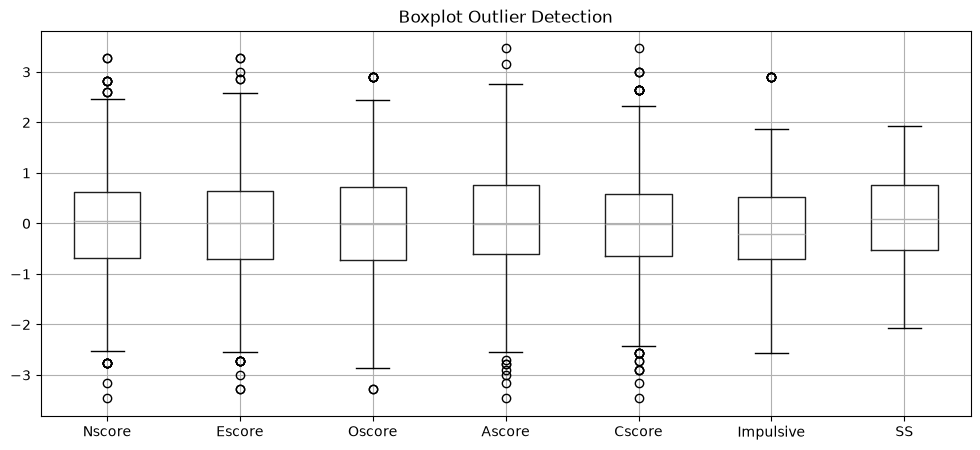


Number of outliers in column 'Nscore': 19 | Lower bound: -2.64 | Upper bound: 2.59

Number of outliers in column 'Escore': 14 | Lower bound: -2.69 | Upper bound: 2.64

Number of outliers in column 'Oscore': 9 | Lower bound: -2.88 | Upper bound: 2.88

Number of outliers in column 'Ascore': 9 | Lower bound: -2.66 | Upper bound: 2.81

Number of outliers in column 'Cscore': 24 | Lower bound: -2.51 | Upper bound: 2.44

Number of outliers in column 'Impulsive': 7 | Lower bound: -2.57 | Upper bound: 2.39

Number of outliers in column 'SS': 0 | Lower bound: -2.46 | Upper bound: 2.70

Number of outlier rows: 81

Total outliers: 82


In [14]:
# 1. Plot Boxplot to detect outliers in key numeric columns
num_cols = [
    'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
    'Impulsive', 'SS'
]
plt.figure(figsize=(12, 5))
df_clean[num_cols].boxplot()
plt.title('Boxplot Outlier Detection')
plt.show()

# 2. Calculate IQR thresholds for important columns
is_outlier = pd.DataFrame(False, index=df_clean.index, columns=num_cols)
for col in num_cols:
  Q1 = df_clean[col].quantile(0.25)
  Q3 = df_clean[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  # 3. Detect outliers
  is_outlier[col] = np.where((df_clean[col] > upper_bound) | (df_clean[col] < lower_bound), True, False)

  outlier = np.where((df_clean[col] > upper_bound) | (df_clean[col] < lower_bound), 1, 0).sum()

  print(f"\nNumber of outliers in column '{col}': {outlier} | Lower bound: {lower_bound:.2f} | Upper bound: {upper_bound:.2f}")

num_outlier_rows = np.any(is_outlier, axis=1).sum()
print(f"\nNumber of outlier rows: {num_outlier_rows}")

print(f"\nTotal outliers: {is_outlier.sum().sum()}")

























<a id="section-3-5-1"></a>
### 3.5.1 Comments and Rationale for Outlier Handling

- **Columns containing Outliers:**
  - 6/7 cột điểm tâm lý xuất hiện ngoại lệ theo quy tắc IQR gồm `Nscore`, `Escore`, `Oscore`, `Ascore`, `Cscore` và `Impulsive`.
  - Riêng `SS` không có ngoại lệ.

- **Number of Outliers Detected:**
  - Tổng cộng phát hiện 82 giá trị ngoại lệ thuộc 81 bản ghi:
    - `Nscore`: 19
    - `Escore`: 14
    - `Oscore`: 9
    - `Ascore`: 9
    - `Cscore`: 24
    - `Impulsive`: 7
    - `SS`: 0.
  - Số lượng ngoại lệ chiếm tỷ lệ nhỏ (~4,3% tổng số bản ghi).

- **Handling Method (Capping):**
  - Áp dụng kỹ thuật Capping đồng bộ cho cả 7 đặc trưng tâm lý.
  - Các giá trị nhỏ hơn ngưỡng dưới $[Q1 - 1,5 \times IQR]$ được gán về bằng cận dưới; các giá trị lớn hơn ngưỡng trên $[Q3 + 1,5 \times IQR]$ được gán về bằng cận trên.

- **Rationale:**
  - Nhóm lựa chọn Capping thay vì Trimming (xóa dòng) để tránh làm thất thoát dữ liệu và duy trì toàn vẹn kích thước mẫu ban đầu (1.885 dòng).
  - Các giá trị ngoại lệ trong trắc nghiệm tâm lý có thể phản ánh sự đa dạng tự nhiên của tính cách; tuy nhiên, việc capping ở bước này giúp hạn chế sức ảnh hưởng của các điểm số quá cực đoan lên các thuật toán nhạy cảm với khoảng cách hoặc phân phối.

<a id="section-3-6"></a>
## 3.6 Data Cleaning Summary

| Check | Before | After | Interpretation |
| --- | --- | --- | --- |
| Records | 1,885 | 1,885 | Không xóa dòng; capping giữ nguyên cỡ mẫu. |
| Selected columns | 21 | 21 | Chưa thêm biến mục tiêu `User`. |
| Missing values | 0 | 0 | Không cần imputation. |
| Duplicate records, excluding ID | 0 | 0 | Không cần loại trùng. |
| Country and Ethnicity | Quantified numeric codes | Text category labels | Ánh xạ theo bảng mã nguồn. |
| Substance-use fields | CL0–CL6 | Binary 0/1 | CL4–CL6 được gán 1 cho cửa sổ một tháng. |
| Psychological score outliers | 82 values across 81 records | Capped at IQR limits | Chưa loại trừ khả năng đây là các điểm số hợp lệ. |

**Giới hạn của quy trình baseline:** Các ngưỡng IQR ở trên được tính trên toàn bộ dữ liệu trước khi chia Train/Test. Khi phát triển đánh giá chính thức, cần học ngưỡng capping chỉ từ tập Train hoặc từng training fold, rồi áp dụng cùng ngưỡng cho dữ liệu validation/test.

**Kiểm tra tính hợp lệ của khảo sát:** Cột `Semer` không nằm trong 21 cột được chọn. Tệp nguồn có 8 phản hồi khác CL0 cho chất giả Semeron; các bản ghi này vẫn được giữ để bảo toàn baseline gốc. Cần ghi rõ chính sách xử lý và kiểm tra độ nhạy của kết quả khi loại các bản ghi này. Tham khảo [mô tả bộ dữ liệu UCI](https://archive.ics.uci.edu/dataset/373/drug-consumption-quantified).

<a id="target-eda"></a>
<a id="section-4"></a>
# 4. Target Construction and Exploratory Data Analysis

<a id="section-4-1"></a>
## 4.1 Target Construction and Univariate Analysis

`User = 1` nếu có ít nhất một chỉ báo trong tám chất bằng 1; ngược lại `User = 0`. Nhóm Non-User chỉ có nghĩa là không báo cáo sử dụng tám chất này trong tháng trước khảo sát.

In [15]:
# Construct and persist the target together with the cleaned data.
# This rebuilds the table with current labels on every full run.
df_clean['User'] = df_clean[drug_cols].eq(1).any(axis=1).astype('int8')
assert df_clean['User'].isin([0, 1]).all()
assert not df_clean.isna().any().any()

with closing(sqlite3.Connection(database=database_path)) as connection:
    df_clean.to_sql('data_clean', if_exists='replace', con=connection, index=False)

print(f"Saved {len(df_clean):,} records and {df_clean.shape[1]} columns, including User.")
display(df_clean['User'].value_counts().sort_index().rename_axis('User').to_frame('Frequency'))

Saved 1,885 records and 22 columns, including User.


,Frequency
User,
0,964
1,921


,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,SS,Amphet,Cannabis,Coke,Ketamine,LSD,Mushrooms,Legalh,Ecstasy,User
0,1,2,0,5,UK,Mixed-White/Asian,0.31287,-0.57545,-0.58331,-0.91699,...,-1.18084,0,0,0,0,0,0,0,0,0
1,2,1,1,8,UK,White,-0.67825,1.93886,1.43533,0.76096,...,-0.21575,0,1,0,0,0,0,0,1,1
2,3,2,1,5,UK,White,-0.46725,0.80523,-0.84732,-1.62090,...,0.40148,0,0,0,0,0,0,0,0,0
3,4,0,0,7,UK,White,-0.14882,-0.80615,-0.01928,0.59042,...,-1.18084,0,0,0,0,0,0,0,0,0
4,5,2,0,8,UK,White,0.73545,-1.63340,-0.45174,-0.30172,...,-0.21575,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1880,1884,0,0,4,USA,White,-1.19430,1.74091,1.88511,0.76096,...,1.92173,0,1,0,0,0,0,0,0,1
1881,1885,0,1,4,USA,White,-0.24649,1.74091,0.58331,0.76096,...,0.76540,0,0,0,0,1,1,0,0,1
1882,1886,1,0,6,USA,White,1.13281,-1.37639,-1.27553,-1.77200,...,-0.52593,1,1,1,0,0,0,0,1,1
1883,1887,0,0,4,USA,White,0.91093,-1.92173,0.29338,-1.62090,...,1.22470,0,1,0,0,0,0,0,0,1


,User,Frequency
0,0,964
1,1,921


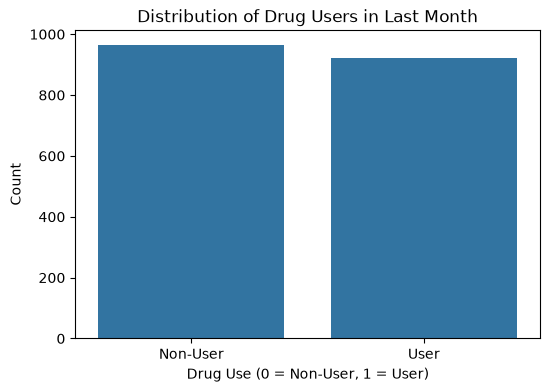

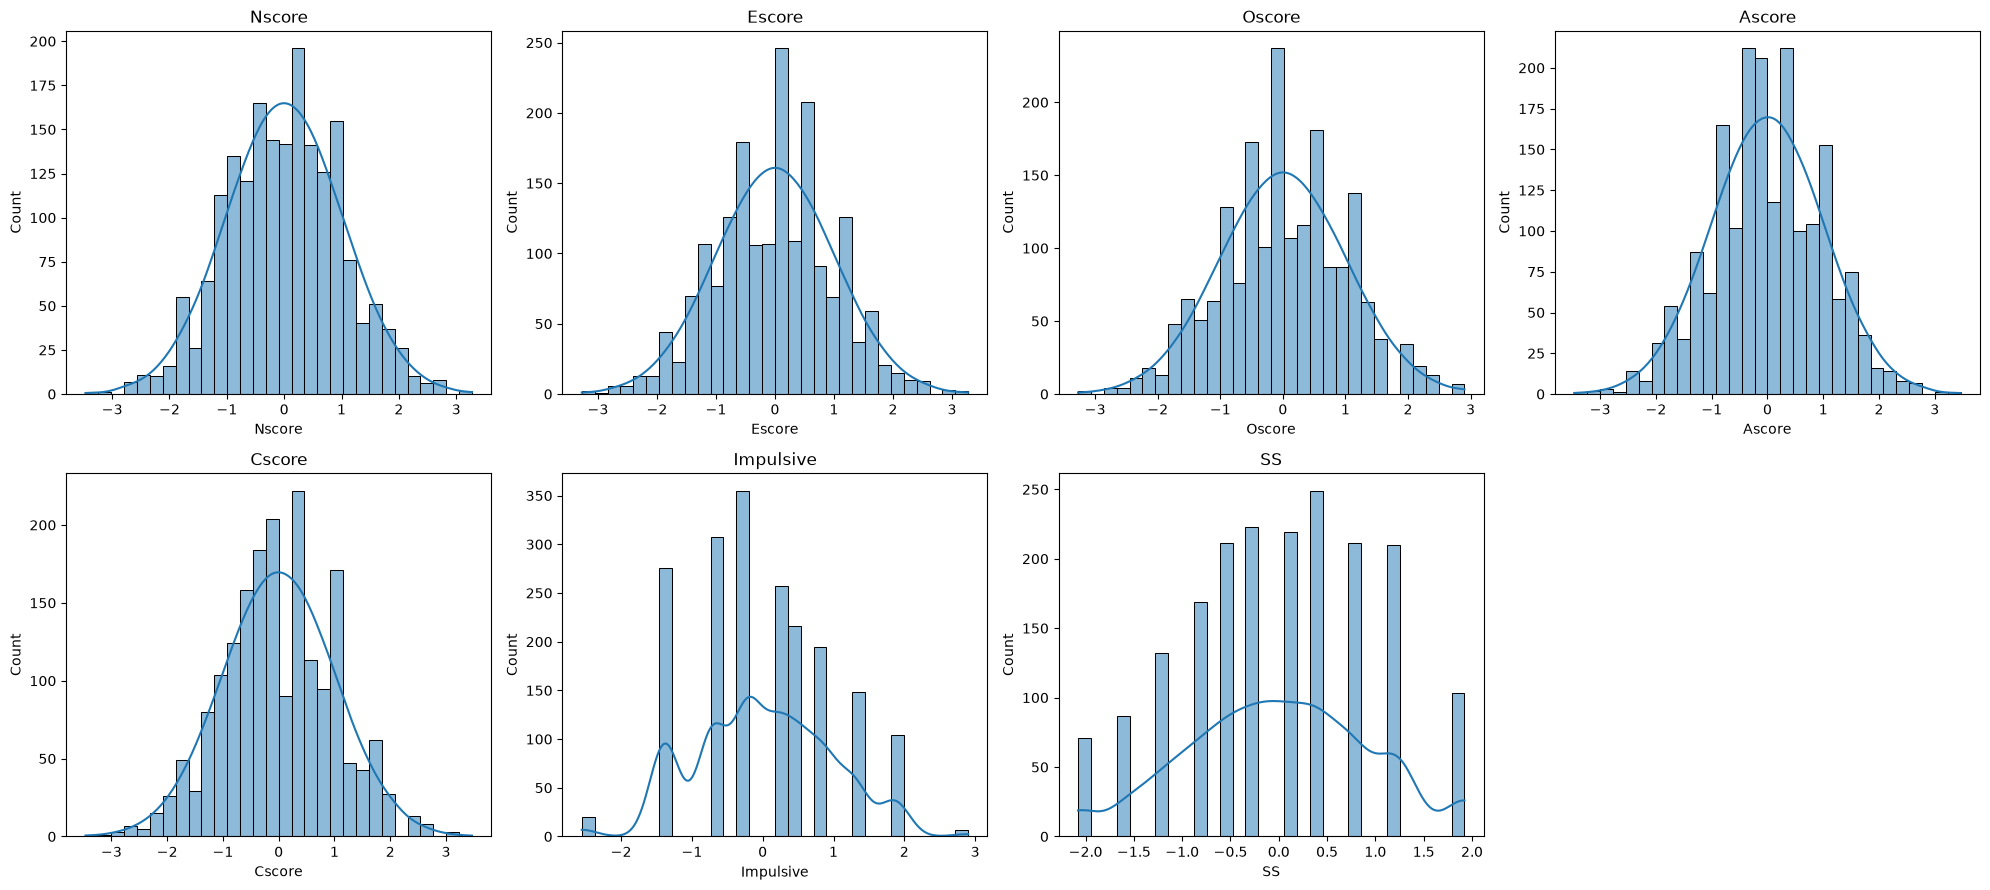

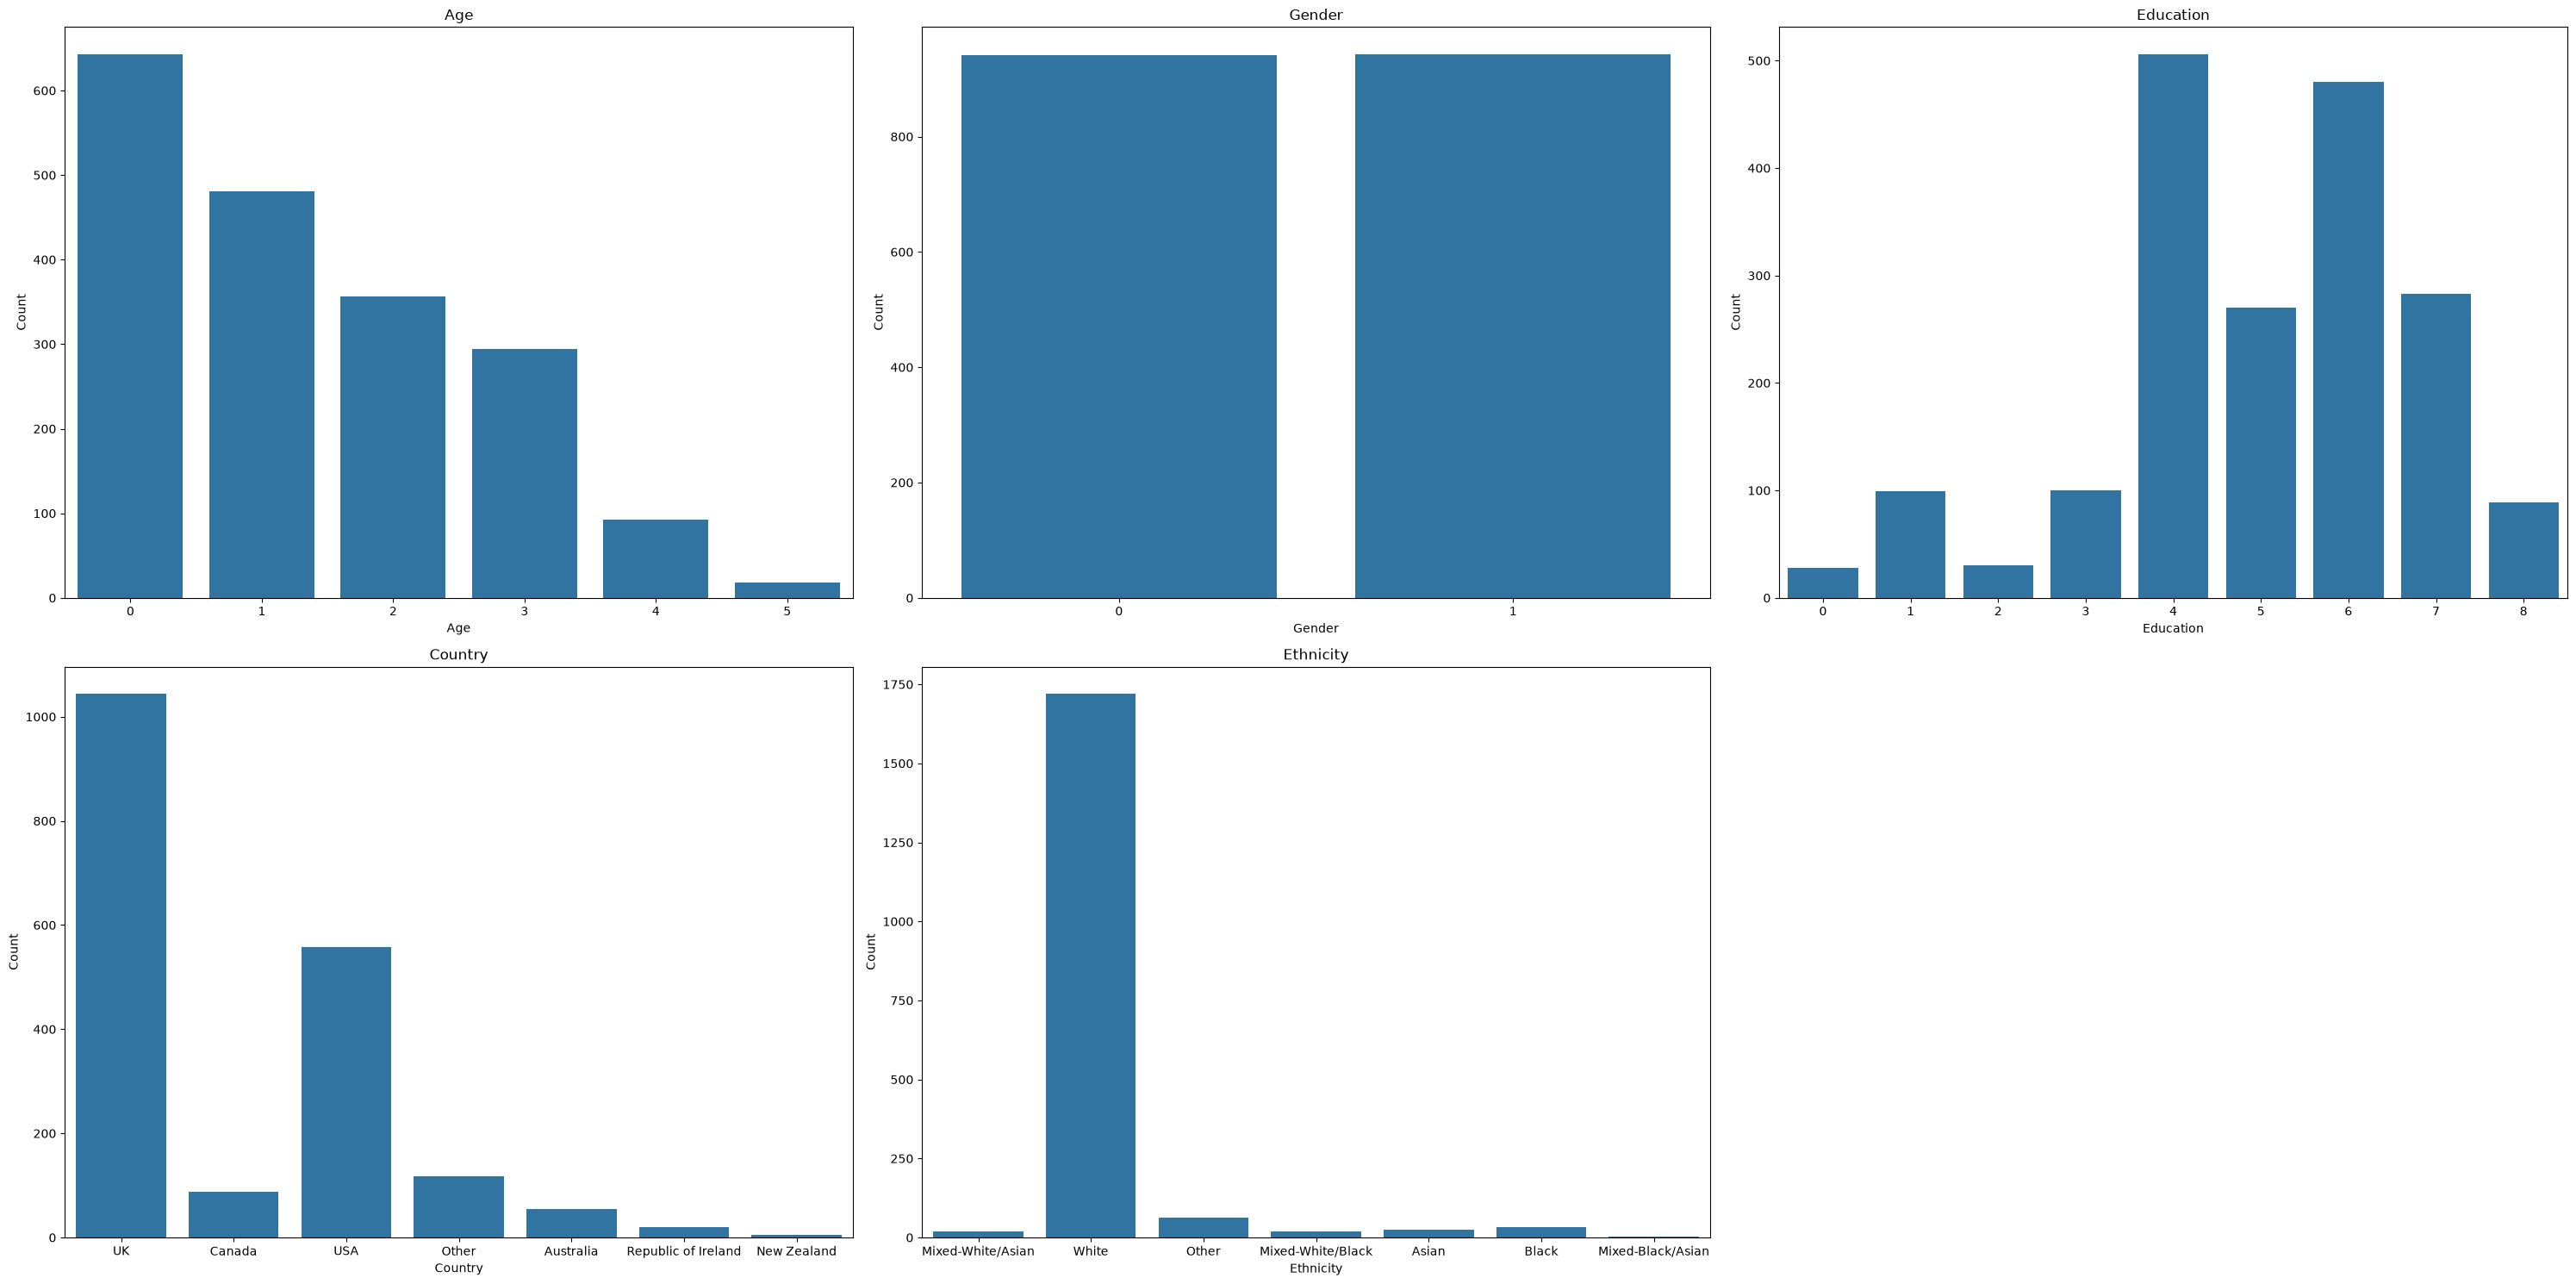

In [16]:
# Load the cleaned data and target created above.
with closing(sqlite3.Connection(database=database_path)) as connection:
  cursor = connection.cursor()
  data_clean = pd.read_sql_query(sql="SELECT * FROM data_clean", con=connection)

  display(data_clean)

  # 4. Print frequency for each User
  frequency_user = pd.read_sql_query("""
    SELECT User, COUNT(*) as Frequency
    FROM data_clean
    GROUP BY User
    ORDER BY User
  """, con=connection)
  
  display(frequency_user)

  # 5. Distribution of Target Variable

  plt.figure(figsize=(6, 4))
  sns.barplot(x=["Non-User", "User"], y=[frequency_user["Frequency"][0], frequency_user["Frequency"][1]])
  plt.title('Distribution of Drug Users in Last Month')
  plt.xlabel('Drug Use (0 = Non-User, 1 = User)')
  plt.ylabel('Count')
  plt.show()

  # 6. Distribution of Numerical Features
  numerical_features = [
      'Nscore', 'Escore', 'Oscore',
      'Ascore', 'Cscore', 'Impulsive', 'SS'
  ]

  cursor.execute("""
    SELECT Nscore, Escore, Oscore, Ascore, Cscore, Impulsive, SS
    FROM data_clean
  """)
  result = cursor.fetchall()

  fig, axes = plt.subplots(2, 4, figsize=(20, 9))
  axes = axes.flatten()

  for i, col in enumerate(numerical_features):
    values = [row[i] for row in result]

    sns.histplot(x=values, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel(col)

  for i in range(7, len(axes)):
    fig.delaxes(axes[i])  

  plt.tight_layout()
  plt.show()


  # 7. Distribution of Categorical Features
  categorical_features = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity']

  cursor.execute("""
    SELECT Age, Gender, Education, Country, Ethnicity
    FROM data_clean
  """)
  result = cursor.fetchall()
  Age = [row[0] for row in result]
  Gender = [row[1] for row in result]
  Education = [row[2] for row in result]
  Country = [row[3] for row in result]
  Ethnicity = [row[4] for row in result]

  categorical_data = [Age, Gender, Education, Country, Ethnicity]

  fig, axes = plt.subplots(2, 3, figsize=(30, 15))
  axes = axes.flatten()

  for i, col in enumerate(categorical_features):
    sns.countplot(x=categorical_data[i], ax=axes[i])

    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

  for i in range(5, len(axes)):
    fig.delaxes(axes[i])

  plt.tight_layout()
  plt.show()

In [17]:
with closing(sqlite3.Connection(database=database_path)) as connection:
  country_query = """
      SELECT 
        Country,
        COUNT(*) AS Count,
        ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM data_clean), 2) AS "Relative Frequency (%)"
      FROM data_clean
      GROUP BY Country 
      ORDER BY Count DESC
  """

  cursor = connection.cursor()
  cursor.execute(country_query)
  
  record = cursor.fetchall()

  print(f"{'Country':<25} {'Count':>8} {'Relative Frequency (%)':>25}")
  for country, count, percentage in record:
      print(f"{country:<25} {count:>8} {percentage:>25}")

Country                      Count    Relative Frequency (%)
UK                            1044                     55.38
USA                            557                     29.55
Other                          118                      6.26
Canada                          87                      4.62
Australia                       54                      2.86
Republic of Ireland             20                      1.06
New Zealand                      5                      0.27


In [18]:
with closing(sqlite3.Connection(database=database_path)) as connection:
    ethnicity_query = """
        SELECT
            Ethnicity,
            COUNT(*) AS Count,
            ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM data_clean), 2)
                AS "Relative Frequency (%)"
        FROM data_clean
        GROUP BY Ethnicity
        ORDER BY Count DESC;
    """
    cursor = connection.cursor()
    cursor.execute(ethnicity_query)
    
    record = cursor.fetchall()

    print(f"{'Ethnicity':<25} {'Count':>8} {'Relative Frequency (%)':>25}")
    for ethnicity, count, percentage in record:
        print(f"{ethnicity:<25} {count:>8} {percentage:>25.2f}")

Ethnicity                    Count    Relative Frequency (%)
White                         1720                     91.25
Other                           63                      3.34
Black                           33                      1.75
Asian                           26                      1.38
Mixed-White/Black               20                      1.06
Mixed-White/Asian               20                      1.06
Mixed-Black/Asian                3                      0.16


<a id="section-4-1-1"></a>
### 4.1.1 Country and Ethnicity Imbalance

**Country:**

- Trong tổng số 1.885 quan sát, UK chiếm 55,38% (1.044 quan sát) và USA chiếm 29,55% (557 quan sát). Như vậy, hai quốc gia này chiếm tổng cộng **84,93%** tập dữ liệu.
- Ngược lại, New Zealand chỉ có 5 quan sát (0,27%) và Republic of Ireland có 20 quan sát (1,06%).
- Sự chênh lệch đáng kể về số lượng quan sát giữa các quốc gia cho thấy dữ liệu có tính đại diện địa lý hạn chế. Việc sử dụng Country làm đặc trưng dự đoán có thể khiến mô hình học chủ yếu những mối quan hệ đặc trưng cho UK và USA, trong khi các nhóm quốc gia ít được đại diện không có đủ quan sát để mô hình học các mẫu đáng tin cậy.

**Ethnicity:**

- Phân phối của Ethnicity mất cân bằng nghiêm trọng, khi nhóm White chiếm 91,25% (1.720 quan sát), trong khi sáu nhóm còn lại chỉ chiếm tổng cộng 8,75% (165 quan sát).
- Đặc biệt, nhóm Mixed-Black/Asian chỉ có 3 quan sát (0,16%). Kích thước mẫu quá nhỏ của một số nhóm có thể làm tăng độ bất định trong quá trình học và nguy cơ overfitting đối với các nhóm ít được đại diện.

**Kết luận và quyết định Feature Selection:**

Dựa trên kết quả EDA, nhóm quyết định loại bỏ hai đặc trưng `Country` và `Ethnicity` khỏi tập dữ liệu đầu vào nhằm:

- Hạn chế sự phụ thuộc trực tiếp của mô hình vào các đặc trưng nhân khẩu học có phân phối mất cân bằng nghiêm trọng.
- Giảm nguy cơ học các mối quan hệ không ổn định từ những nhóm có kích thước mẫu quá nhỏ.
- Tập trung phân tích các đặc trưng về độ tuổi, giới tính, trình độ học vấn và đặc điểm tâm lý của người tham gia.

<a id="section-4-1-2"></a>
### 4.1.2 Comments and Insights

**1. Target Variable Distribution:**

- Biến mục tiêu `User` có phân phối tương đối cân bằng, với **964 Non-Users (51,14%)** và **921 Users (48,86%)** trên tổng số 1.885 quan sát.
- Sự chênh lệch giữa hai lớp chỉ khoảng **2,28%**, cho thấy không tồn tại hiện tượng mất cân bằng lớp nghiêm trọng.
- Do đó, nhóm chưa cần áp dụng các kỹ thuật xử lý mất cân bằng lớp

**2. Key Feature Distributions:**

- **Age:** Phân phối tập trung nhiều vào các nhóm tuổi trẻ. Trong đó, Age = 0 có số lượng quan sát lớn nhất với 643 người (34,11%). Số lượng quan sát nhìn chung giảm dần ở các nhóm tuổi lớn hơn. Điều này cho thấy mẫu nghiên cứu có xu hướng tập trung vào những người trẻ tuổi.

- **Gender:** Phân phối gần như cân bằng tuyệt đối giữa hai nhóm, với Gender = 0 có 942 quan sát và Gender = 1 có 943 quan sát. Điều này cho thấy không có sự mất cân bằng đáng kể về số lượng giữa hai nhóm giới tính trong tập dữ liệu.

- **Education:** Phân phối không đồng đều giữa các nhóm trình độ học vấn. Đặc biệt, Education = 4 có 506 quan sát và Education = 6 có 480 quan sát, trong khi một số nhóm khác chỉ có số lượng quan sát tương đối nhỏ. Điều này cho thấy mẫu nghiên cứu tập trung chủ yếu vào một số nhóm trình độ học vấn nhất định.

- **Country and Ethnicity:** Cả hai đặc trưng đều có phân phối mất cân bằng đáng kể. UK và USA chiếm tổng cộng **84,93%** số quan sát, trong khi nhóm White chiếm **91,25%**. Sự tập trung dữ liệu vào một số nhóm nhân khẩu học cho thấy tính đại diện của mẫu nghiên cứu còn hạn chế đối với những nhóm ít được quan sát.

- **Personality Scores (Nscore, Escore, Oscore, Ascore, Cscore):** Các biểu đồ Histogram kết hợp KDE cho thấy những đặc trưng này có phân phối xấp xỉ chuẩn (Approximately Normal Distribution), với phần lớn giá trị tập trung quanh mức trung tâm gần 0 và tần suất giảm dần về hai phía. Điều này cho thấy phần lớn người tham gia có điểm tính cách gần mức trung bình của mẫu, trong khi các giá trị quá cao hoặc quá thấp ít xuất hiện hơn. Phân phối tương đối đối xứng cũng cho thấy các biến không có hiện tượng Skewness nghiêm trọng.

- **Impulsive and SS (Sensation Seeking):** Hai đặc trưng này có phân phối rời rạc (Discrete Distribution) với số lượng giá trị riêng biệt tương đối ít và xuất hiện nhiều đỉnh trong biểu đồ. Điều này phản ánh sự tập trung của các quan sát tại những mức điểm nhất định. Do đó, việc diễn giải phân phối của hai biến này cần chú ý đến tính rời rạc thay vì chỉ dựa vào đường KDE.

**3. Overall Insight:**

Nhìn chung, tập dữ liệu có biến mục tiêu tương đối cân bằng, tạo điều kiện thuận lợi cho việc xây dựng và đánh giá các mô hình Binary Classification mà không cần xử lý mất cân bằng lớp nghiêm trọng.

Tuy nhiên, một số đặc trưng nhân khẩu học như Age, Education, Country và Ethnicity có phân phối không đồng đều, cho thấy những hạn chế về tính đại diện của mẫu nghiên cứu.

Trong khi đó, các đặc trưng tính cách có xu hướng phân phối tương đối đối xứng và tập trung quanh giá trị trung tâm, giúp mô tả đặc điểm tâm lý chung của những người tham gia khảo sát.

Tuy nhiên, **hình dạng phân phối của các đặc trưng không trực tiếp phản ánh khả năng dự đoán biến mục tiêu**. Vì vậy, nhóm sẽ tiếp tục sử dụng Bivariate Analysis, Correlation Analysis và Model Evaluation để đánh giá mối liên hệ giữa các đặc trưng và hành vi sử dụng chất.

<a id="section-4-2"></a>
## 4.2 Bivariate Analysis

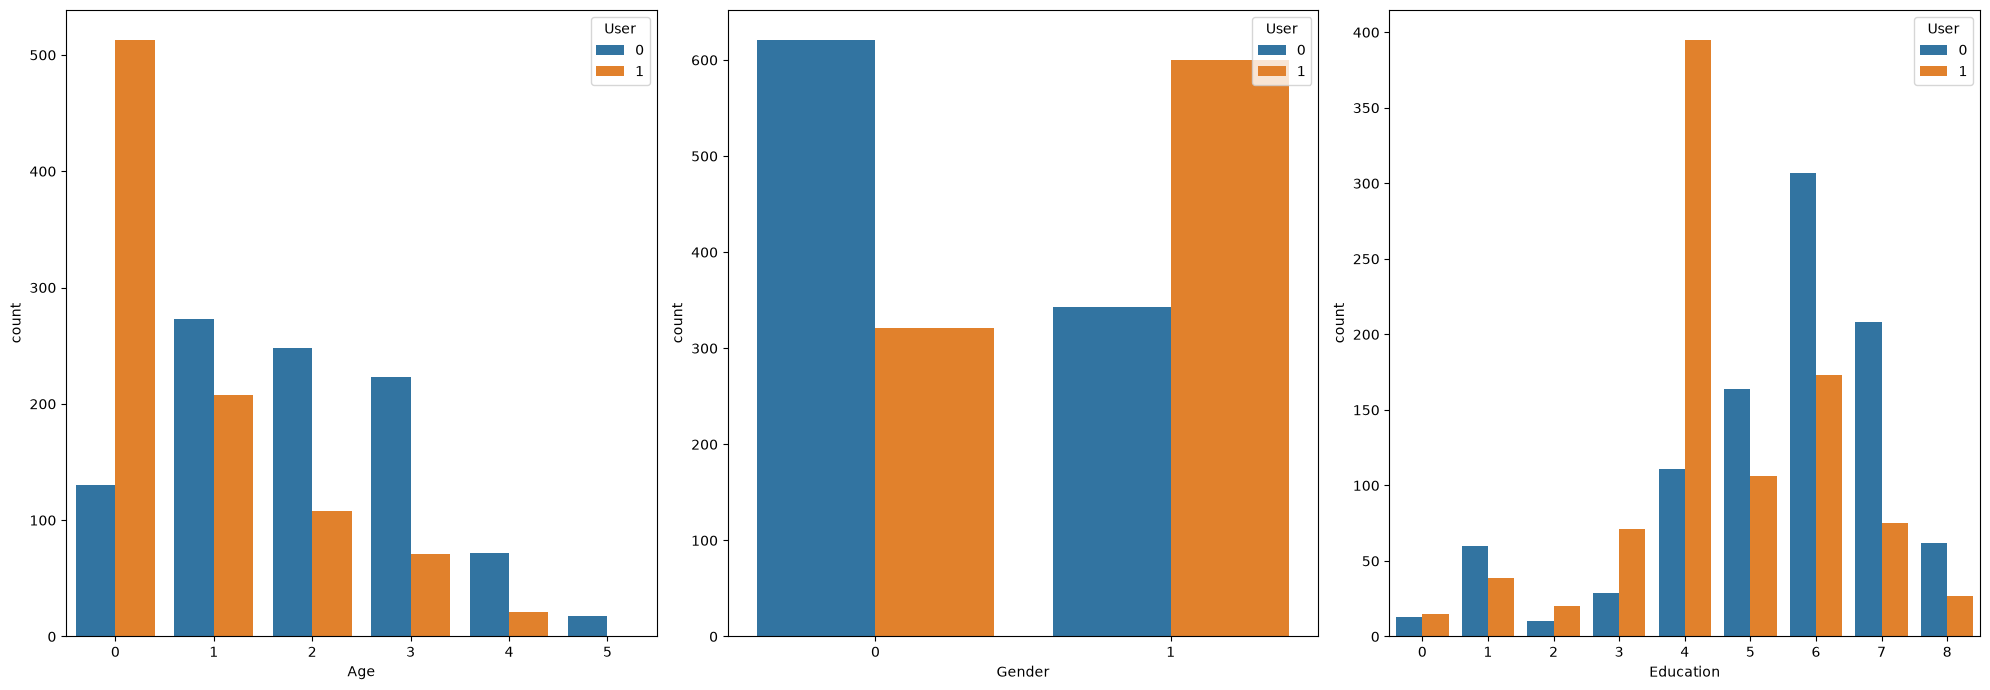

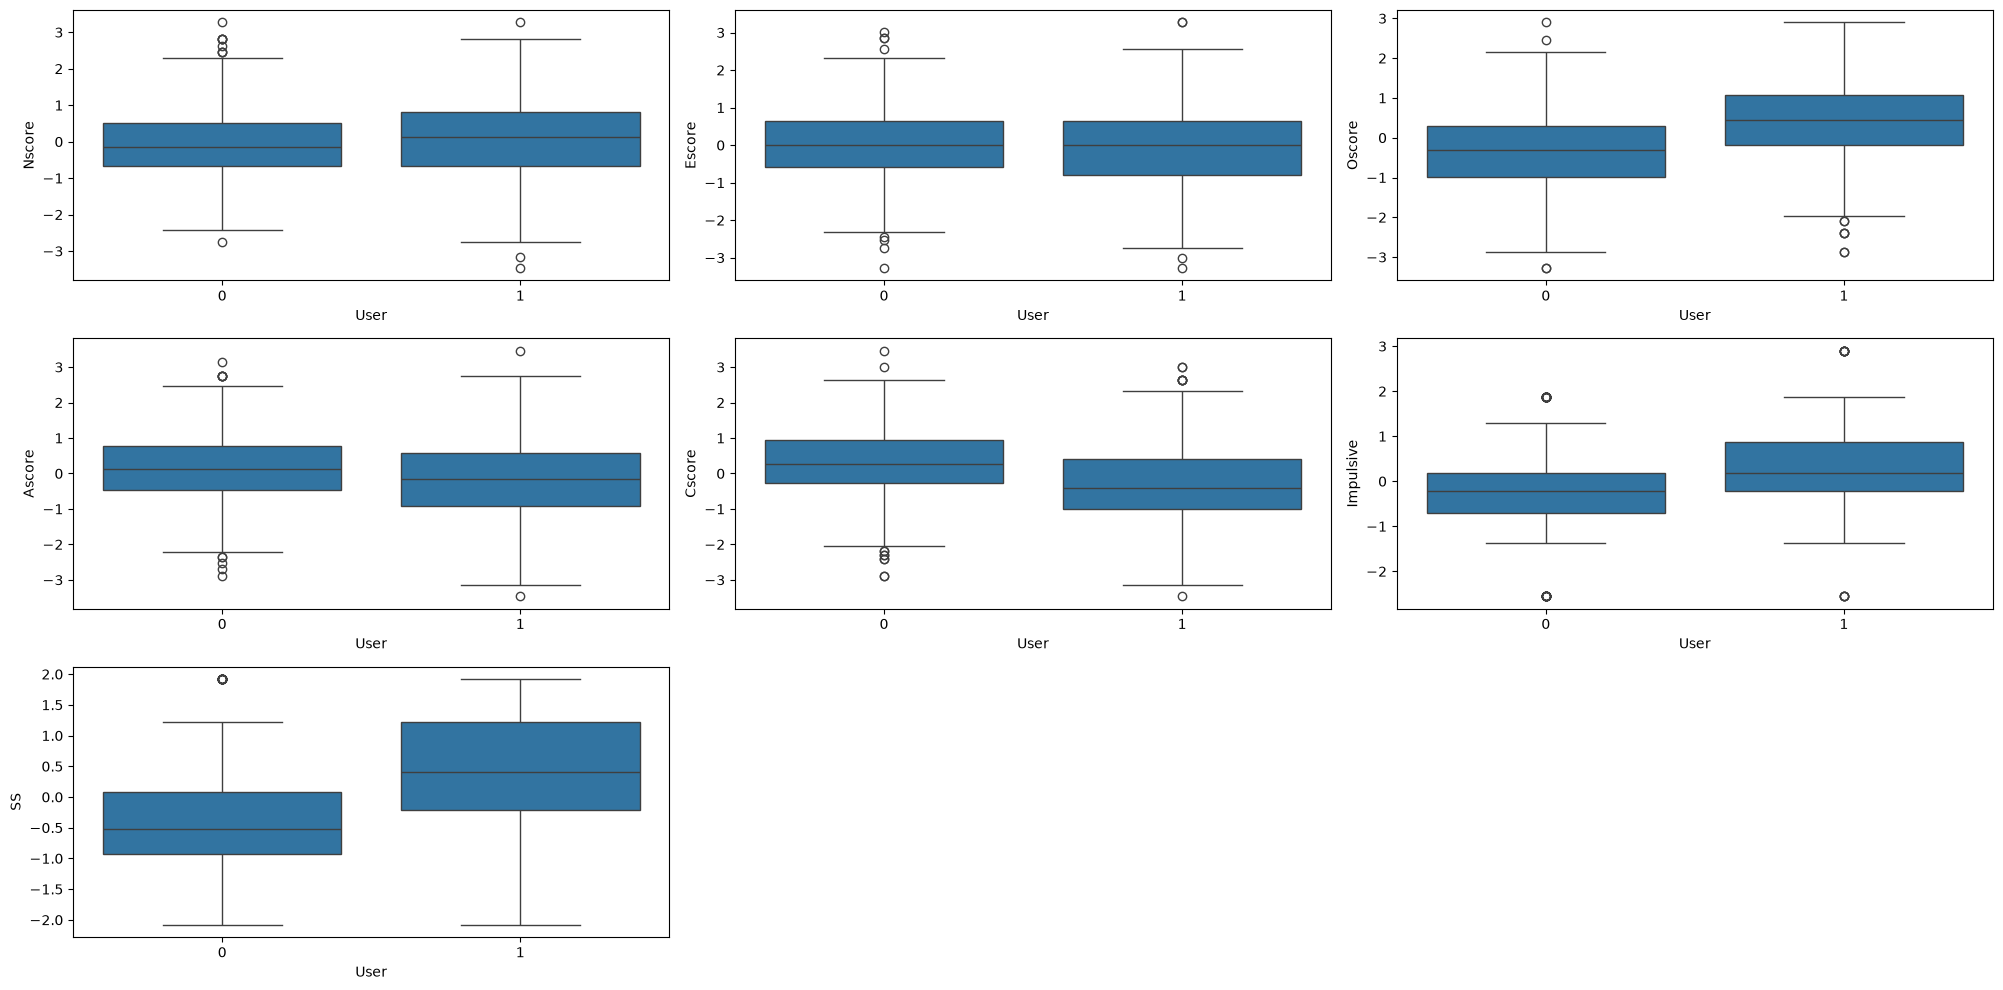

In [19]:
# 1. Categorical Features vs Target
categorical_features = [
    'Age', 'Gender', 'Education'
]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
axes = axes.flatten()
for i, col in enumerate(categorical_features):
  sns.countplot(data=data_clean, x=col, hue="User", ax=axes[i])
  axes[i].legend(title="User", loc="upper right")
plt.tight_layout()
plt.show()

# 2. Numerical Features vs Target
numerical_features = [
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
  sns.boxplot(data=data_clean, x="User", y=col, ax=axes[i])
for i in range(7, 9):
  fig.delaxes(axes[i])
plt.tight_layout()
plt.show()

<a id="section-4-2-1"></a>
### 4.2.1 Comments and Insights

**Đặc trưng phân loại:**
- Age: có mối liên hệ rõ rệt với biến `User`, trong đó nhóm tuổi trẻ nhất có số lượng User vượt trội so với Non-user, trong khi ở các nhóm tuổi lớn hơn, Non-user chiếm ưu thế.
- Gender: Nhóm Gender = 1 có nhiều User hơn Non-User một cách đáng kể, trong khi nhóm Gender = 0 thì lại phản ánh Non-User nhiều hơn User một cách đáng kể. Điều này cho thấy tỷ lệ User khác biệt đáng kể giữa hai nhóm giới tính.
- Education: Nhóm Education = 4 có số lượng User nhiều hơn một cách áp đảo so với Non-User. Ngược lại, các nhóm Education = 6, 7 và 8 có số lượng Non-User lớn hơn User, gợi ý rằng trình độ học vấn có mối liên hệ với biến mục tiêu.

**Đặc trưng số:**
- **Openness (Oscore):** Nhóm User có median cao hơn rõ rệt so với Non-user, cho thấy người sử dụng chất có xu hướng cởi mở với trải nghiệm mới hơn.
- **Impulsivity:** Nhóm User có median cao hơn Non-user, đồng thời khoảng tứ phân vị (IQR) dịch chuyển về phía giá trị cao hơn, cho thấy xu hướng bốc đồng có liên hệ với hành vi sử dụng chất.
- **Sensation Seeking (SS):** Có sự khác biệt nổi bật giữa median của hai nhóm. Điều này cho thấy người có xu hướng tìm kiếm cảm giác mạnh thường xuất hiện nhiều hơn trong nhóm User.
- **Neuroticism (Nscore):** Nhóm User có median cao hơn nhẹ so với Non-user, tuy nhiên phân phối hai nhóm chồng lấn đáng kể nên mức độ khác biệt không quá rõ rệt.
- **Extraversion (Escore):** Median của cả hai nhóm đều gần 0 và IQR tương đối giống nhau, cho thấy đặc trưng này ít thể hiện sự khác biệt giữa User và Non-user.
- **Agreeableness (Ascore):** Nhóm User có median thấp hơn Non-user, cho thấy xu hướng điểm Agreeableness thấp hơn ở nhóm sử dụng chất.
- **Conscientiousness (Cscore):** Nhóm User có median thấp hơn đáng kể so với Non-user cho thấy người sử dụng chất có xu hướng đạt điểm Conscientiousness thấp hơn.

**Nhận xét chung:** Oscore, Cscore và SS thể hiện sự khác biệt về median tương đối rõ rệt giữa hai nhóm User và Non-user, tiếp theo là Impulsivity và Ascore. Nscore có khác biệt nhẹ, trong khi Escore gần như tương đồng. Nhìn chung, các đặc điểm tính cách và yếu tố nhân khẩu học có mối liên hệ với hành vi sử dụng các chất thuộc Ecstasy pleiad. Tuy nhiên, các phân phối vẫn có sự chồng lấn đáng kể, cho thấy không có đặc trưng đơn lẻ nào đủ để phân biệt hoàn toàn hai nhóm.

<a id="section-4-3"></a>
## 4.3 Correlation Analysis

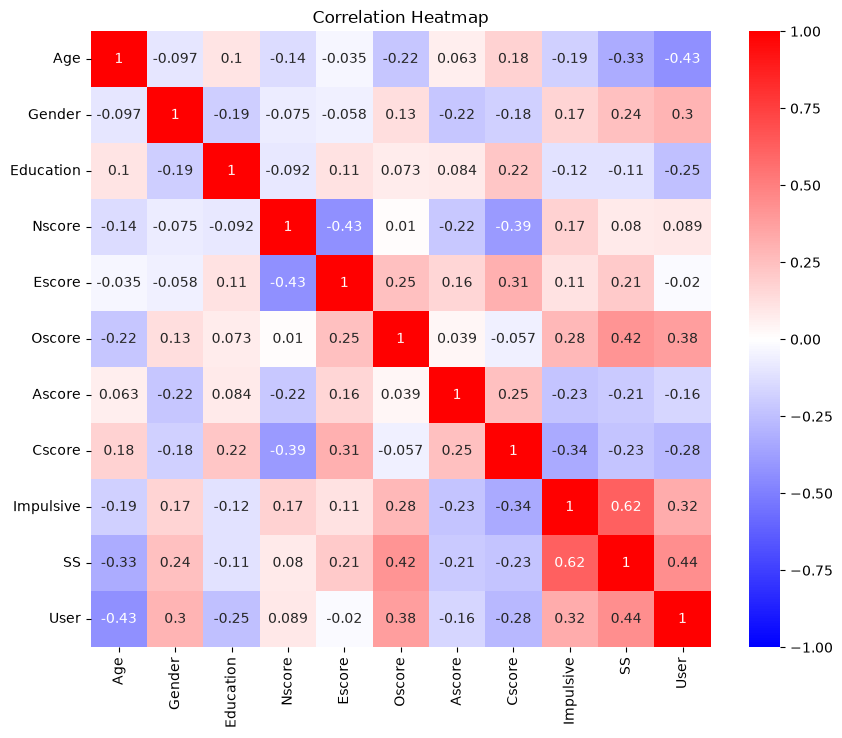

Top correlated attributes with User:


SS           0.441983
Age         -0.430927
Oscore       0.376373
Impulsive    0.320409
Gender       0.295580
Cscore      -0.276849
Education   -0.249354
Ascore      -0.161282
Nscore       0.089005
Escore      -0.020222
Name: User, dtype: float64

In [20]:
features = [
    'Age', 'Gender', 'Education',
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS', 'User'
]

plt.figure(figsize=(10, 8))
correlation_matrix = data_clean[features].corr()
sns.heatmap(data=correlation_matrix, annot=True, cmap='bwr', vmax=1, vmin=-1)
plt.title('Correlation Heatmap')
plt.show()

# Identify top correlated attributes with User
target_corr = correlation_matrix['User'].drop('User')
top_corr_idx = np.argsort(np.abs(target_corr))[::-1]
print("Top correlated attributes with User:")
target_corr.iloc[top_corr_idx]

<a id="section-4-3-1"></a>
### 4.3.1 Key Business Takeaways

**1. Top Positive Correlations (Tương quan dương mạnh nhất):**

- **SS (r = 0.442):** Có tương quan dương cao nhất với biến mục tiêu User. Điều này cho thấy những người có xu hướng tìm kiếm cảm giác mạnh cao có khả năng thuộc nhóm User lớn hơn.
- **Oscore (r = 0.376):** Có tương quan dương với User, cho thấy những người có tính cách cởi mở và thích trải nghiệm mới có xu hướng thuộc nhóm User nhiều hơn.
- **Impulsive (r = 0.320):** Có tương quan dương với User, cho thấy những người có mức độ bốc đồng cao có xu hướng thuộc nhóm User nhiều hơn.

**2. Top Negative Correlations (Tương quan âm mạnh nhất):**

- **Age (r = -0.431):** Có tương quan âm lớn nhất với biến mục tiêu User. Điều này cho thấy nhóm người trẻ tuổi có xu hướng sử dụng ít nhất một chất thuộc danh sách nghiên cứu trong tháng gần nhất nhiều hơn so với các nhóm tuổi lớn hơn.
- **Cscore (r = -0.279):** Có tương quan âm với User, cho thấy những người có tính tận tâm và khả năng tự kiểm soát cao có xu hướng ít thuộc nhóm User hơn.
- **Education (r = -0.249):** Có tương quan âm với User theo cách mã hóa hiện tại, gợi ý rằng trình độ học vấn có thể liên quan đến hành vi sử dụng chất.

**3. Multicollinearity Check (Kiểm tra đa cộng tuyến):**

- Dựa trên Correlation Heatmap, không có cặp đặc trưng đầu vào nào có hệ số tương quan tuyệt đối vượt ngưỡng 0.8.
- Cặp **Impulsive và SS** có tương quan dương cao nhất (r ≈ 0.62), nhưng vẫn thấp hơn ngưỡng 0.8.
- Các cặp đặc trưng khác có mức tương quan thấp hoặc trung bình, chẳng hạn Nscore và Escore (r ≈ -0.43), Oscore và SS (r ≈ 0.42).
- Vì vậy, chưa phát hiện dấu hiệu đa cộng tuyến nghiêm trọng dựa trên ma trận tương quan Pearson. Các đặc trưng có thể được tiếp tục sử dụng trong quá trình xây dựng mô hình.

**4. Kết luận:**

Các kết quả cho thấy **SS, Age, Oscore và Impulsive** là những đặc trưng có mối liên hệ tuyến tính đáng chú ý nhất với biến mục tiêu User.

Điều này gợi ý rằng độ tuổi và các đặc điểm tâm lý, đặc biệt là xu hướng tìm kiếm cảm giác mạnh, sự cởi mở và tính bốc đồng, có thể đóng vai trò quan trọng trong việc dự đoán hành vi sử dụng chất.

Tuy nhiên, tương quan không chứng minh quan hệ nhân quả và không trực tiếp phản ánh mức độ quan trọng của đặc trưng trong mô hình Machine Learning.

<a id="section-4-4"></a>
## 4.4 Multivariate Analysis

<a id="section-4-4-1"></a>
### 4.4.1 Data Preparation for Multivariate Analysis

In [21]:
# Prepare shared groups for the three multivariate analyses.
multi_df = data_clean[['Age','SS','Impulsive','Gender','User']].copy()

multi_df['Age_group'] = pd.cut(
    multi_df['Age'],
    bins=[-1, 0, 1, 5],
    labels=['18-24', '25-34', '35+']
)

multi_df['SS_group'] = pd.qcut(
    multi_df['SS'],
    q=3,
    labels=['low', 'medium', 'high']
)

multi_df['Impulsive_group'] = pd.qcut(
    multi_df['Impulsive'],
    q=3,
    labels=['low', 'medium', 'high']
)

multi_df.head()

,Age,SS,Impulsive,Gender,User,Age_group,SS_group,Impulsive_group
0,2,-1.18084,-0.21712,0,0,35+,low,low
1,1,-0.21575,-0.71126,1,1,25-34,medium,low
2,2,0.40148,-1.37983,1,0,35+,medium,low
3,0,-1.18084,-1.37983,0,0,18-24,low,low
4,2,-0.21575,-0.21712,0,0,35+,medium,low


<a id="section-4-4-2"></a>
### 4.4.2 Age × SS × User

,Age_group,SS_group,User_rate,Sample_size
0,18-24,low,53.28,122
1,18-24,medium,79.58,240
2,18-24,high,91.46,281
3,25-34,low,19.77,172
4,25-34,medium,45.66,173
5,25-34,high,69.85,136
6,35+,low,16.22,376
7,35+,medium,30.58,278
8,35+,high,50.47,107


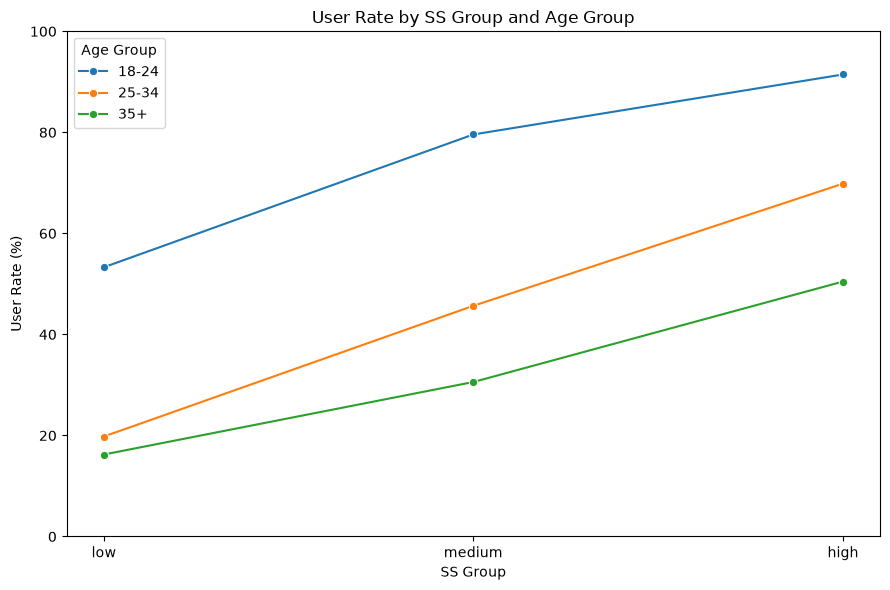

In [22]:
# Age x SS x User: summarize and plot User rates for this combination.
summary_ss_age = (
    multi_df.groupby(['Age_group', 'SS_group'], observed=True)['User']
    .agg(User_rate='mean', Sample_size='size')
    .reset_index()
)
summary_ss_age['User_rate'] = (summary_ss_age['User_rate'] * 100).round(2)
display(summary_ss_age)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=summary_ss_age, x='SS_group', y='User_rate',
    hue='Age_group', marker='o', ax=ax
)
ax.set_title('User Rate by SS Group and Age Group')
ax.set_xlabel('SS Group')
ax.set_ylabel('User Rate (%)')
ax.set_ylim(0, 100)
ax.legend(title='Age Group')
plt.tight_layout()
plt.show()


<a id="section-4-4-2-1"></a>
#### 4.4.2.1 Group Interpretation

**Vì sao chọn tổ hợp này?**

**Age x SS x User:** Trong Phần 4.3, Tuổi và SS có hai hệ số tương quan tuyệt đối mạnh nhất với User, nhưng theo hai chiều ngược nhau (Age: r = -0,431; SS: r = 0,442). Kết hợp hai biến giúp khảo sát liệu mối liên hệ giữa SS và tỷ lệ User có tương tự ở các nhóm tuổi hay không, đồng thời xem các nhóm tuổi có còn khác biệt khi so sánh ở cùng mức SS hay không.

**Diễn giải biểu đồ:**

So sánh tỷ lệ User giữa các mức SS trong từng nhóm tuổi, cũng như giữa các nhóm tuổi tại cùng một mức SS. Hãy xem tỷ lệ phần trăm cùng với cỡ mẫu trong bảng; tỷ lệ ở các nhóm con có ít quan sát có thể biến động nhiều.

<a id="section-4-4-3"></a>
### 4.4.3 Gender × SS × User

,Gender,SS_group,User_rate,Sample_size
0,0,low,15.72,439
1,0,medium,40.06,317
2,0,high,67.20,186
3,1,low,39.39,231
4,1,medium,60.96,374
5,1,high,83.14,338


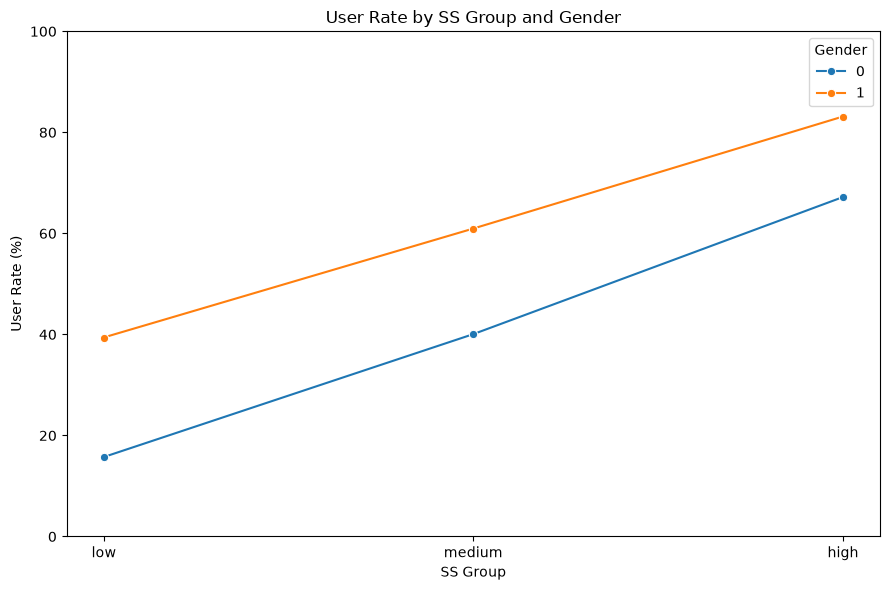

In [23]:
# Gender x SS x User: summarize and plot User rates for this combination.
summary_ss_gender = (
    multi_df.groupby(['Gender', 'SS_group'], observed=True)['User']
    .agg(User_rate='mean', Sample_size='size')
    .reset_index()
)
summary_ss_gender['User_rate'] = (summary_ss_gender['User_rate'] * 100).round(2)
display(summary_ss_gender)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=summary_ss_gender, x='SS_group', y='User_rate',
    hue='Gender', marker='o', ax=ax
)
ax.set_title('User Rate by SS Group and Gender')
ax.set_xlabel('SS Group')
ax.set_ylabel('User Rate (%)')
ax.set_ylim(0, 100)
ax.legend(title='Gender')
plt.tight_layout()
plt.show()


<a id="section-4-4-3-1"></a>
#### 4.4.3.1 Group Interpretation

**Vì sao chọn tổ hợp này?**

**Giới tính x SS x User:** Phân tích hai biến cho thấy phân phối User khác nhau giữa hai nhóm giới tính. So sánh tỷ lệ User theo các mức SS trong từng nhóm giới tính giúp khảo sát liệu mối liên hệ với SS có xuất hiện ở cả hai nhóm hay không, và liệu khác biệt giới tính có còn duy trì khi so sánh ở cùng mức SS hay không. Tỷ lệ giúp việc so sánh rõ hơn số lượng tuyệt đối khi cỡ mẫu giữa các nhóm con khác nhau.

**Diễn giải biểu đồ:**

So sánh tỷ lệ User giữa các mức SS trong từng nhóm giới tính, cũng như giữa hai nhóm tại cùng một mức SS. Hãy xem tỷ lệ phần trăm cùng với cỡ mẫu trong bảng; tỷ lệ ở các nhóm con có ít quan sát có thể biến động nhiều.

<a id="section-4-4-4"></a>
### 4.4.4 Impulsivity × SS × User

,Impulsive_group,SS_group,User_rate,Sample_size
0,low,low,21.04,537
1,low,medium,47.38,325
2,low,high,78.12,96
3,medium,low,28.57,105
4,medium,medium,52.31,216
5,medium,high,75.00,152
6,high,low,60.71,28
7,high,medium,58.67,150
8,high,high,78.62,276


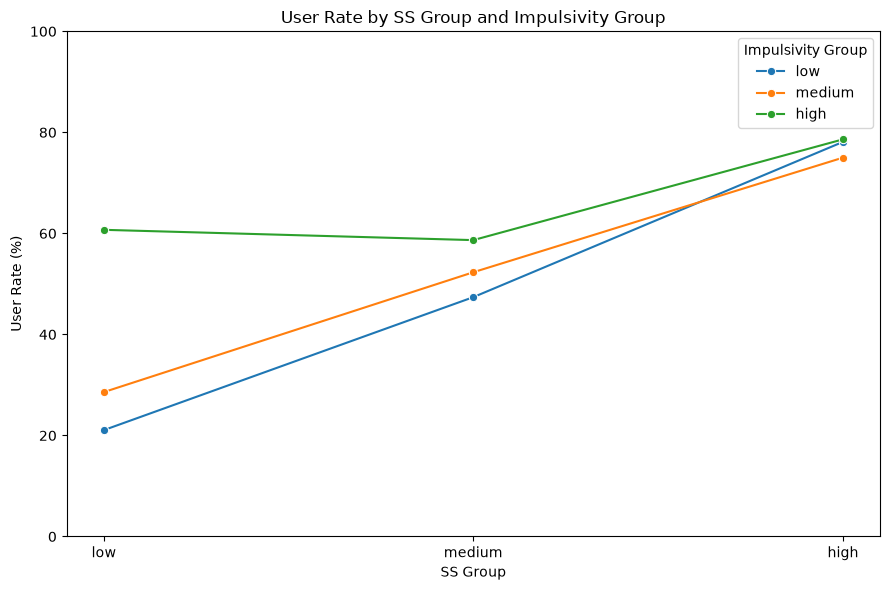

In [24]:
# Impulsive x SS x User: summarize and plot User rates for this combination.
summary_ss_impulsive = (
    multi_df.groupby(['Impulsive_group', 'SS_group'], observed=True)['User']
    .agg(User_rate='mean', Sample_size='size')
    .reset_index()
)
summary_ss_impulsive['User_rate'] = (summary_ss_impulsive['User_rate'] * 100).round(2)
display(summary_ss_impulsive)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=summary_ss_impulsive, x='SS_group', y='User_rate',
    hue='Impulsive_group', marker='o', ax=ax
)
ax.set_title('User Rate by SS Group and Impulsivity Group')
ax.set_xlabel('SS Group')
ax.set_ylabel('User Rate (%)')
ax.set_ylim(0, 100)
ax.legend(title='Impulsivity Group')
plt.tight_layout()
plt.show()


<a id="section-4-4-4-1"></a>
#### 4.4.4.1 Group Interpretation

**Vì sao chọn tổ hợp này?**

**IMPULSIVE x SS x User:** Cả hai đặc điểm đều tương quan thuận với User (IMPULSIVE: r = 0,320; SS: r = 0,442), đồng thời cũng tương quan với nhau (r xấp xỉ 0,62). Xem xét đồng thời hai đặc điểm giúp khảo sát liệu mức cao ở cả hai có đi kèm tỷ lệ User cao hơn hay không, và SS có giúp phân biệt về mặt mô tả trong từng nhóm bốc đồng hay không.

**Diễn giải biểu đồ:**

So sánh tỷ lệ User giữa các mức SS trong từng nhóm Implusive, cũng như giữa các nhóm tại cùng một mức SS. Hãy xem tỷ lệ phần trăm cùng với cỡ mẫu trong bảng; tỷ lệ ở các nhóm con có ít quan sát có thể biến động nhiều.

<a id="section-4-4-5"></a>
### 4.4.5 Overall Interpretation

**Cách diễn giải phân tích:**

- SS được dùng làm trục so sánh chung vì có tương quan thuận mạnh nhất với User trong số các biến dự báo được chọn. Age, Gender và Implusive bổ sung bối cảnh nhân khẩu học và tâm lý cho mối liên hệ này.
- Tuổi được chia thành các nhóm 18–24, 25–34 và từ 35 trở lên để dễ theo dõi; SS và Implusive được chia thành các nhóm thấp, trung bình và cao theo phân vị. Mỗi tổ hợp sử dụng User làm kết quả, vì vậy đây là các phân tích đa biến gồm ba biến.
- Hãy xem mỗi tỷ lệ User cùng với cỡ mẫu tương ứng. Các nhóm con nhỏ có thể tạo ra tỷ lệ thiếu ổn định. Những biểu đồ này mô tả mối liên hệ; chúng không chứng minh quan hệ nhân quả hay xác nhận tác động tương tác bằng kiểm định thống kê.

<a id="feature-engineering"></a>
<a id="section-5"></a>
# 5. Data Preparation

This section prepares the cleaned data for modeling through categorical feature encoding, a stratified train/test split, and scaling fitted on the training data.


<a id="section-5-1"></a>
## 5.1 Categorical Feature Encoding

In [25]:
# 1. Select features
features = [
    'Age', 'Gender', 'Education',
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]   

# 2. One-Hot Encoding
df_encoded = pd.get_dummies(
    data_clean[features + ['User']],
    columns=['Age', 'Education'],
    drop_first=True,
    dtype=np.int8
)

display(df_encoded.head())

,Gender,Nscore,Escore,Oscore,Ascore,Cscore,Impulsive,SS,User,Age_1,...,Age_4,Age_5,Education_1,Education_2,Education_3,Education_4,Education_5,Education_6,Education_7,Education_8
0,0,0.31287,-0.57545,-0.58331,-0.91699,-0.00665,-0.21712,-1.18084,0,0,...,0,0,0,0,0,0,1,0,0,0
1,1,-0.67825,1.93886,1.43533,0.76096,-0.14277,-0.71126,-0.21575,1,1,...,0,0,0,0,0,0,0,0,0,1
2,1,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,-1.37983,0.40148,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0,-0.14882,-0.80615,-0.01928,0.59042,0.58489,-1.37983,-1.18084,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0.73545,-1.63340,-0.45174,-0.30172,1.30612,-0.21712,-0.21575,0,0,...,0,0,0,0,0,0,0,0,0,1


<a id="section-5-1-1"></a>
### 5.1.1 Comments and Rationale

**1. Encoding Method Selected (Phương pháp mã hóa):**

- Nhóm sử dụng **One-Hot Encoding** cho hai đặc trưng Age và Education vì đây là các biến phân loại đã được mã hóa bằng số. One-Hot Encoding giúp biểu diễn từng nhóm bằng các cột nhị phân (0 và 1), tránh việc mô hình hiểu nhầm các giá trị mã hóa là khoảng cách số học.
- Gender là biến phân loại nhị phân đã được mã hóa bằng số nên được giữ nguyên.

**2. Scaling Technique Selected (Phương pháp chuẩn hóa):**

- Nhóm lựa chọn **StandardScaler** để chuẩn hóa 7 đặc trưng tâm lý: Nscore, Escore, Oscore, Ascore, Cscore, Impulsive và SS.
- StandardScaler đưa các đặc trưng về thang đo có trung bình bằng 0 và độ lệch chuẩn bằng 1, giúp các đặc trưng có thang đo khác nhau không chi phối mô hình chỉ vì độ lớn giá trị.
- So với MinMaxScaler, StandardScaler không giới hạn dữ liệu trong khoảng [0, 1]. Tuy nhiên, cả hai phương pháp đều nhạy cảm với giá trị ngoại lai, dù vậy các giá trị outliers cũng không đến mức cực kì nghiêm trọng.

<a id="section-5-2"></a>
## 5.2 Train/Test Split and Feature Scaling

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate Features (X) and Target (y)
X = df_encoded[[
  'Gender', 'Age_1', 'Age_2', 'Age_3', 'Age_4', 'Age_5',
  'Education_1', 'Education_2', 'Education_3', 'Education_4',
  'Education_5', 'Education_6', 'Education_7', 'Education_8',
  'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS'
]]
y = df_encoded['User']

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Feature Scaling
num_cols = [
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (1508, 21), X_test shape: (377, 21)


<a id="section-5-2-1"></a>
### 5.2.1 Split and Stratification Rationale

**Split Ratio (Tỷ lệ chia dữ liệu):**

- Nhóm chia dữ liệu theo tỷ lệ 80% cho tập huấn luyện (Train) và 20% cho tập kiểm tra (Test).
- Tập Train được sử dụng để huấn luyện mô hình, trong khi tập Test dùng để đánh giá khả năng dự đoán trên dữ liệu chưa từng được sử dụng để huấn luyện.
- `random_state=42` giúp đảm bảo kết quả chia dữ liệu có thể tái lập.

**Stratification (Phân chia dữ liệu theo tỷ lệ lớp):**

- Nhóm sử dụng `stratify=y` nhằm duy trì tỷ lệ User và Non-user tương đối giống nhau giữa hai tập Train và Test.
- Mặc dù dữ liệu tương đối cân bằng (48,86% User và 51,14% Non-user), stratification vẫn giúp hạn chế sai lệch phân bố lớp khi chia dữ liệu.

<a id="model-evaluation"></a>
<a id="section-6"></a>
# 6. Baseline Model Training and Evaluation

<a id="section-6-1"></a>
## 6.1 Baseline Model Training

Hai mô hình sử dụng cấu hình baseline; báo cáo này chưa thực hiện tìm kiếm siêu tham số. Kết quả trên cùng một tập Test dùng để so sánh sơ bộ, chưa phải đánh giá độc lập sau chọn mô hình.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Initialize Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# 2. Train Models and Collect Metrics
test_results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

print(">>>Test result")
results_df = pd.DataFrame(test_results)
display(results_df)

>>>Test result


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.782493,0.831169,0.695652,0.757396,0.870720
1,Random Forest,0.766578,0.807692,0.684783,0.741176,0.853838


<a id="section-6-2"></a>
## 6.2 Model Comparison and Visualization

Best Performing Model: Logistic Regression


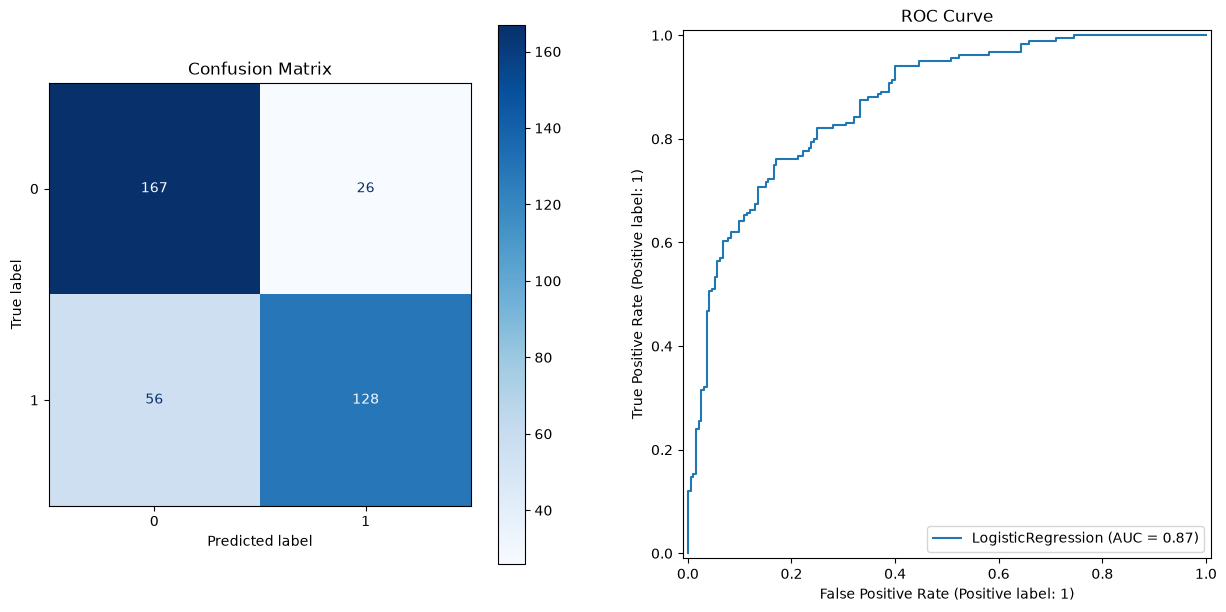

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Plot Confusion Matrix for Best Model
best_model_name = results_df.loc[results_df["F1"].idxmax(), "Model"]
best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes = axes.flatten()
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

# 2. Plot ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
plt.title('ROC Curve')
plt.show()

<a id="section-6-3"></a>
## 6.3 Model Evaluation and Discussion

<a id="section-6-3-1"></a>
### 6.3.1 Best Performing Model (Mô hình tốt nhất)

- Trong hai mô hình được thử nghiệm gồm Logistic Regression và Random Forest, **Logistic Regression** đạt F1-Score cao nhất (**0.7574**), đồng thời có Accuracy cao nhất (**78,25%**) và ROC-AUC cao nhất (**0.8705**).
- Random Forest có hiệu suất tương đối gần Logistic Regression, với F1-Score = **0.7485** và ROC-AUC = **0.8538**.
- Dựa trên F1-Score, nhóm tạm thời lựa chọn **Logistic Regression là mô hình tốt nhất** trong hai mô hình trên tập Test hiện tại.
- Tuy nhiên, sự chênh lệch hiệu suất giữa Logistic Regression và Random Forest tương đối nhỏ. Do đó, kết quả lựa chọn mô hình cần được kiểm chứng thêm thông qua Cross-Validation và Hyperparameter Tuning trong bước mở rộng tiếp theo để đánh giá tính ổn định và khả năng tổng quát hóa.

<a id="section-6-3-2"></a>
### 6.3.2 Key Metric Comparison (So sánh các chỉ số)

Nhóm sử dụng **F1-Score** làm tiêu chí đánh giá chính vì đây là trung bình điều hòa giữa Precision và Recall, giúp đánh giá sự cân bằng giữa khả năng dự đoán chính xác nhóm User và khả năng phát hiện những User thực tế.

Kết quả đánh giá hai mô hình trên tập Test:

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7825 | 0.8312 | 0.6957 | 0.7574 | 0.8705 |
| Random Forest | 0.7719 | 0.8101 | 0.6957 | 0.7485 | 0.8538 |

**Nhận xét:**

- **Precision (83,12%):** Trong số những người được Logistic Regression dự đoán là User, có 83,12% thực sự thuộc nhóm User.
- **Recall (69,57%):** Mô hình phát hiện đúng 69,57% tổng số User thực tế, cho thấy vẫn còn một tỷ lệ đáng kể User bị bỏ sót.
- **F1-Score (0.7574):** Logistic Regression đạt mức cân bằng giữa Precision và Recall tốt nhất trong hai mô hình được thử nghiệm.
- **ROC-AUC (0.8705):** Cho thấy Logistic Regression có khả năng phân biệt tương đối tốt giữa hai nhóm User và Non-User khi xét trên nhiều ngưỡng phân loại khác nhau.
- Logistic Regression và Random Forest có Recall bằng nhau (0.6957), nhưng Logistic Regression đạt Precision và F1-Score cao hơn.

<a id="section-6-3-3"></a>
### 6.3.3 Trade-offs and Error Analysis (Phân tích sai số)

Dựa trên Confusion Matrix của Logistic Regression trên **377 quan sát thuộc tập Test**:

- **True Positive (TP = 128):** Mô hình dự đoán chính xác 128 trường hợp thực tế thuộc nhóm User.
- **True Negative (TN = 167):** Mô hình dự đoán chính xác 167 trường hợp thực tế thuộc nhóm Non-User.
- **False Positive (FP = 26):** Có 26 trường hợp thực tế là Non-User nhưng bị dự đoán thành User, tương đương **13,47% tổng số Non-User thực tế**. Việc phân loại sai này có thể dẫn đến đánh giá không chính xác tình trạng sử dụng chất và gây nguy cơ gán nhãn hoặc kỳ thị cá nhân nếu kết quả được sử dụng không phù hợp.
- **False Negative (FN = 56):** Có 56 trường hợp thực tế là User nhưng bị dự đoán thành Non-User, tương đương **30,43% tổng số User thực tế**. Điều này cho thấy mô hình vẫn bỏ sót một tỷ lệ đáng kể những người thuộc nhóm User.

<a id="section-6-3-3-1"></a>
#### 6.3.3.1 Precision and Recall Trade-off

- Nếu mục tiêu ứng dụng là hỗ trợ sàng lọc nhằm cung cấp các chương trình giáo dục hoặc phòng ngừa tự nguyện, việc giảm False Negative có thể được ưu tiên để hạn chế bỏ sót đối tượng cần hỗ trợ.
- Tuy nhiên, việc giảm ngưỡng phân loại nhằm tăng Recall thường có thể làm tăng False Positive và giảm Precision.
- Vì vậy, cần cân nhắc giữa khả năng phát hiện User và nguy cơ phân loại nhầm Non-User, đặc biệt khi nghiên cứu liên quan đến thông tin cá nhân nhạy cảm.

<a id="section-6-3-4"></a>
### 6.3.4 Evaluation Conclusion

Logistic Regression đạt hiệu suất tốt nhất trong hai mô hình baseline trên tập Test hiện tại, với F1-Score = **0.7574** và ROC-AUC = **0.8705**. Tuy nhiên, Recall chỉ đạt 69,57%, cho thấy mô hình vẫn bỏ sót khoảng 30,43% số User thực tế.

Do đó, Logistic Regression được lựa chọn làm mô hình baseline tốt nhất trong báo cáo baseline này. Trong bước mở rộng tiếp theo, nhóm sẽ tiếp tục sử dụng Cross-Validation, Hyperparameter Tuning và xem xét điều chỉnh Classification Threshold trên dữ liệu validation nhằm cải thiện hiệu suất, đặc biệt là Recall, đồng thời kiểm soát Precision và F1-Score.

<a id="discussion"></a>
<a id="section-7"></a>
# 7. Discussion, Conclusions and Recommendations

<a id="section-7-1"></a>
## 7.1 Core Findings and Model Summary (Kết quả chính và tổng kết mô hình)

- Nghiên cứu sử dụng **1.885 quan sát** nhằm xây dựng mô hình phân loại trạng thái sử dụng ít nhất một trong tám chất được lựa chọn thuộc nhóm Ecstasy pleiad trong tháng gần nhất, dựa trên các đặc điểm nhân khẩu học và tâm lý.
- Biến mục tiêu `User` có phân phối tương đối cân bằng, với **48,86% User** và **51,14% Non-User**, giúp hai lớp có mức độ đại diện khá đồng đều trong tập dữ liệu.
- Kết quả EDA và Correlation Analysis cho thấy các đặc trưng tâm lý như **Sensation Seeking (r = 0.442)**, **Openness (r = 0.376)** và **Impulsivity (r = 0.320)** có tương quan dương đáng chú ý với biến mục tiêu. Ngược lại, **Age (r = -0.431)** và **Conscientiousness (r ≈ -0.279)** có tương quan âm. Điều này gợi ý rằng độ tuổi và các đặc điểm tâm lý có thể cung cấp thông tin hữu ích cho bài toán phân loại hành vi sử dụng chất.
- Nhóm đã thử nghiệm hai mô hình gồm Logistic Regression và Random Forest. Dựa trên kết quả đánh giá trên tập Test, **Logistic Regression** được lựa chọn làm mô hình tốt nhất với **Accuracy = 78,25%, F1-Score = 0.7574 và ROC-AUC = 0.8705**.
- Tuy nhiên, Recall của Logistic Regression chỉ đạt **69,57%**, tương ứng với việc mô hình bỏ sót 56 trong tổng số 184 User thực tế trên tập Test. Điều này cho thấy mô hình vẫn có những hạn chế cần cải thiện trước khi xem xét bất kỳ ứng dụng thực tế nào.

<a id="section-7-2"></a>
## 7.2 Actionable Business Recommendations (Đề xuất ứng dụng thực tế)

<a id="section-7-2-1"></a>
### 7.2.1 Nghiên cứu các yếu tố liên quan đến hành vi sử dụng chất

- Ưu tiên nghiên cứu sâu hơn các đặc điểm tâm lý có tương quan đáng chú ý với User, đặc biệt là Sensation Seeking, Impulsivity và Openness, nhằm hiểu rõ mối liên hệ giữa tính cách và hành vi sử dụng chất.
- Sử dụng các kết quả phân tích ở cấp độ tổng hợp để xác định những chủ đề cần được chú trọng trong hoạt động giáo dục và truyền thông, chẳng hạn như hành vi tìm kiếm cảm giác mạnh, bốc đồng,...
- Các mối tương quan chỉ phản ánh sự liên hệ, không đủ bằng chứng để khẳng định những đặc điểm tâm lý này là nguyên nhân trực tiếp dẫn đến hành vi sử dụng chất.

<a id="section-7-2-2"></a>
### 7.2.2 Hỗ trợ thiết kế các chương trình giáo dục và phòng ngừa

- Kết quả EDA cho thấy nhóm tuổi trẻ có xu hướng thuộc nhóm User nhiều hơn. Vì vậy, có thể ưu tiên nghiên cứu nhu cầu giáo dục và nâng cao nhận thức của nhóm người trẻ, chẳng hạn thông qua các chương trình truyền thông trong trường học, đại học hoặc cộng đồng.
- Nội dung chương trình có thể tập trung vào tác động của việc sử dụng chất, kỹ năng ra quyết định, khả năng kiểm soát hành vi và cách tiếp cận các nguồn hỗ trợ đáng tin cậy.
- Đánh giá hiệu quả chương trình bằng các khảo sát trước và sau hoạt động, đo lường sự thay đổi về kiến thức, nhận thức rủi ro và mức độ tiếp cận thông tin.
- Việc lựa chọn đối tượng tham gia nên dựa trên nhu cầu thực tế và nguyên tắc tự nguyện, không gán nhãn hoặc kỳ thị cá nhân dựa trên đặc điểm tâm lý hay kết quả dự đoán.

<a id="section-7-2-3"></a>
### 7.2.3 Phát triển công cụ hỗ trợ nghiên cứu và phân tích dữ liệu

- Có thể phát triển một công cụ phân tích sử dụng Logistic Regression nhằm minh họa mối liên hệ giữa các đặc điểm đầu vào và xác suất dự đoán thuộc nhóm User trong phạm vi dữ liệu nghiên cứu.
- Công cụ nên tập trung vào phân tích thống kê, trực quan hóa dữ liệu và đánh giá hiệu suất mô hình, thay vì sử dụng kết quả dự đoán để xác định tình trạng sử dụng chất của từng cá nhân.
- Trước khi xem xét áp dụng ngoài phạm vi nghiên cứu, cần kiểm tra khả năng tổng quát hóa, độ tin cậy của xác suất dự đoán và những rủi ro liên quan đến quyền riêng tư, thiên lệch dữ liệu và việc phân loại sai.

<a id="section-7-3"></a>
## 7.3 Future Improvements and Limitations (Hạn chế và hướng phát triển)

<a id="section-7-3-1"></a>
### 7.3.1 Bổ sung và đa dạng hóa dữ liệu

- Thu thập thêm các yếu tố như môi trường sống, điều kiện kinh tế, ảnh hưởng từ bạn bè và hoàn cảnh gia đình để nghiên cứu những mối liên hệ mà bộ dữ liệu hiện tại chưa phản ánh đầy đủ.
- Mở rộng kích thước mẫu và tăng mức độ đa dạng về quốc gia, sắc tộc và nhóm tuổi nhằm cải thiện tính đại diện và khả năng khái quát hóa của kết quả.

<a id="section-7-3-2"></a>
### 7.3.2 Khắc phục hạn chế của dữ liệu

- Bộ dữ liệu tập trung chủ yếu ở UK và USA, đồng thời phần lớn người tham gia thuộc nhóm White. Điều này có thể hạn chế khả năng áp dụng kết quả cho các quần thể khác.
- Dữ liệu về hành vi sử dụng chất được thu thập thông qua phương pháp tự báo cáo (Self-reported Data), do đó có thể tồn tại sai lệch.
- Nghiên cứu mang tính quan sát nên chưa thể thiết lập quan hệ nhân quả giữa các đặc điểm tâm lý và hành vi sử dụng chất.

<a id="section-7-3-3"></a>
### 7.3.3 Tối ưu hóa và đánh giá mô hình

- Sử dụng **GridSearchCV kết hợp Stratified K-Fold Cross-Validation** để tìm bộ siêu tham số phù hợp và đánh giá mức độ ổn định của mô hình.
- Thử nghiệm **Classification Threshold Tuning** nhằm cải thiện Recall và giảm số lượng False Negative, đồng thời kiểm soát Precision và F1-Score để hạn chế gia tăng False Positive.

<a id="section-7-3-4"></a>
### 7.3.4 Phát triển ứng dụng minh họa

- Trong tương lai, có thể sử dụng **Streamlit** để xây dựng giao diện trực quan hóa dữ liệu, so sánh các mô hình và minh họa kết quả phân loại trong môi trường nghiên cứu.
- Cần đảm bảo các nguyên tắc về bảo mật, quyền riêng tư và sử dụng dữ liệu có trách nhiệm. Kết quả mô hình không nên được xem là bằng chứng xác nhận hành vi sử dụng chất hoặc sử dụng để đưa ra quyết định bất lợi đối với cá nhân.

<a id="section-7-4"></a>
## 7.4 Evaluation Limitations and Reproducibility

- **Preprocessing:** IQR capping được học từ toàn bộ dữ liệu. Cần chuyển các phép biến đổi học từ dữ liệu vào pipeline, fit chỉ trong tập Train hoặc training folds.
- **Model selection:** Cùng tập Test được dùng để so sánh và lựa chọn mô hình. Các chỉ số trình bày là baseline sơ bộ; cần chọn cấu hình/ngưỡng bằng validation hoặc cross-validation trước khi đánh giá trên tập Test độc lập.
- **Survey validity:** Baseline giữ cả 8 bản ghi báo cáo sử dụng Semeron. Cần nghiên cứu ảnh hưởng của các bản ghi này và nêu rõ tiêu chí giữ/loại.
- **Generalization:** Mẫu khảo sát tự báo cáo, tập trung chủ yếu ở UK/USA và nhóm White; kết quả không đại diện cho toàn bộ dân số.
- **Reproducibility:** Cố định `random_state=42` ở phép chia dữ liệu và Random Forest. Các phiên bản thư viện của lần chạy đã lưu được in ở ô cuối.

In [29]:
import sys
from importlib.metadata import version

print('Python:', sys.version.split()[0])
for package in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn']:
    print(f'{package}: {version(package)}')

Python: 3.11.9
numpy: 2.4.4
pandas: 3.0.3
matplotlib: 3.11.1
seaborn: 0.13.2
scikit-learn: 1.9.0


<a id="section-7-5"></a>
## 7.5 References

- [UCI: Drug Consumption (Quantified)](https://archive.ics.uci.edu/dataset/373/drug-consumption-quantified)
- [Fehrman et al.: The Five Factor Model of Personality and Evaluation of Drug Consumption Risk](https://arxiv.org/abs/1506.06297)
- [scikit-learn: Data Leakage and Recommended Practices](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)